# Transforms and Loading

In [ ]:
%%writefile requirements.txt
pillow
numpy
opencv-python
ultralytics
monai

Writing requirements.txt


In [ ]:
!pip install -r requirements.txt

INFO: pip is looking at multiple versions of torchvision to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 31.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 104.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 766.6/766.6 MB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 120.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 91.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 61.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 5.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB

In [ ]:
import cv2
import os
import torch
from torch.utils.data import Dataset, DataLoader

import numpy as np
import os
from monai.transforms import (
    LoadImaged, EnsureChannelFirstd, Orientationd, Spacingd, ScaleIntensityRanged, Resized,
    RandCropByPosNegLabeld, RandFlipd, RandRotate90d, RandShiftIntensityd,
    RandAffined, RandZoomd, RandGaussianNoised, Compose, EnsureTyped, ToTensord, NormalizeIntensityd, RandGridDistortiond, Lambdad
)


import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

!unzip "/content/drive/MyDrive/RAI_KneeJointSpace/data/jsw_dataset_final.zip" -d "/content"

Mounted at /content/drive
Archive:  /content/drive/MyDrive/RAI_KneeJointSpace/data/jsw_dataset_final.zip
   creating: /content/test/
   creating: /content/train/
   creating: /content/val/
   creating: /content/test/images/
   creating: /content/test/images_side/
   creating: /content/test/labels/
   creating: /content/test/masks/
  inflating: /content/test/jsw_measurements.csv  
  inflating: /content/test/labels/9433580.txt  
  inflating: /content/test/labels/9275159.txt  
  inflating: /content/test/labels/9734247.txt  
  inflating: /content/test/labels/9169092.txt  
  inflating: /content/test/labels/9436006.txt  
  inflating: /content/test/labels/9256066.txt  
  inflating: /content/test/labels/9438742.txt  
  inflating: /content/test/labels/9797760.txt  
  inflating: /content/test/labels/9731542.txt  
  inflating: /content/test/labels/9225871.txt  
  inflating: /content/test/labels/9411118.txt  
  inflating: /content/test/labels/9295400.txt  
  inflating: /content/test/labels/9685324

In [ ]:
TRAIN = '/content/data/train/images_side'
VAL = '/content/data/val/images_side'
TEST = '/content/data/test/images_side'
TRAIN_MASKS = '/content/data/train/masks/'
VAL_MASKS = '/content/data/val/masks'
TEST_MASKS = '/content/data/test/masks'
BATCH_SIZE = 8
LR = 1e-3

UNET_HEIGHT = 256
UNET_WIDTH = 256
DEVICE = 'cuda'
NUM_CLASSES = 2

In [ ]:
class SegmentationDataset(Dataset):
    def __init__(self, images_dir, masks_dir, device, transform=None):
        self.images_dir = images_dir
        self.masks_dir = masks_dir
        self.transform = transform
        self.device = device

        self.image_filenames = sorted(os.listdir(images_dir))
        self.masks_filenames = sorted(os.listdir(masks_dir))

        self.samples = []
        self.masks = []

        for sample in self.image_filenames:
            image_path = os.path.join(self.images_dir, sample)
            image = cv2.imread(image_path, cv2.IMREAD_COLOR)
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = image.astype(np.float32) / 255.0
            image = np.transpose(image, (2, 0, 1))
            self.samples.append(image)

        for sample in self.masks_filenames:
            mask_path = os.path.join(self.masks_dir, sample)
            mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

            mask = np.expand_dims(mask, axis=0).astype(np.int64)
            self.masks.append(mask)


    def __len__(self):
        return len(self.image_filenames)

    def __getitem__(self, index):
        sample = {"image": self.samples[index], "mask": self.masks[index]}

        if self.transform:
            sample = self.transform(sample)

        return torch.tensor(sample["image"]).to(self.device), (torch.tensor(sample["mask"]) / 254).long().to(self.device)

In [ ]:
def convert_mask_dtype(mask):
    return mask.squeeze(0).long()


def get_transforms(mode="train"):
    base_transforms = [
        Spacingd(keys=["image", "mask"], pixdim=(1.0, 1.0), mode=("bilinear", "nearest")),
        Resized(keys=["image", "mask"], spatial_size=(UNET_HEIGHT, UNET_WIDTH), mode=("bilinear", "nearest")),
    ]

    if mode == "train":
        augmentation_transforms = [
            RandFlipd(keys=["image", "mask"], spatial_axis=1, prob=0.5),
            RandGridDistortiond(keys=["image", "mask"], prob=0.2, distort_limit=0.03),
            RandGaussianNoised(keys="image", prob=0.2, mean=0.0, std=0.1),
            RandShiftIntensityd(keys="image", offsets=0.1, prob=0.5),
        ]
    else:  # Validation & Test
        augmentation_transforms = []

    return Compose([
            *base_transforms,
            EnsureTyped(keys=["image", "mask"]),  # Move before ToTensord
            *augmentation_transforms,
            ToTensord(keys=["image", "mask"]),
            Lambdad(keys="mask", func=convert_mask_dtype)
        ])

In [ ]:
train_transforms = get_transforms(mode="train")
val_test_transforms = get_transforms(mode="val")

train_dataset = SegmentationDataset(TRAIN, TRAIN_MASKS, device=DEVICE, transform=train_transforms)
val_dataset = SegmentationDataset(VAL, VAL_MASKS, device=DEVICE, transform=val_test_transforms)
test_dataset = SegmentationDataset(TEST, TEST_MASKS, device=DEVICE, transform=val_test_transforms)

train_dataloader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=False)

In [ ]:
len(train_dataset)

714

In [ ]:
images, masks = next(iter(train_dataloader))
print("Image shape:", images.shape)
print("Mask shape:", masks.shape)

/usr/local/lib/python3.12/dist-packages/monai/transforms/spatial/array.py:497: UserWarning: `data_array` is not of type MetaTensor, assuming affine to be identity.
  warnings.warn("`data_array` is not of type MetaTensor, assuming affine to be identity.")
/tmp/ipython-input-970378579.py:39: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(sample["image"]).to(self.device), (torch.tensor(sample["mask"]) / 254).long().to(self.device)


Image shape: torch.Size([8, 3, 256, 256])
Mask shape: torch.Size([8, 256, 256])


In [ ]:
class UNet(nn.Module):
    def __init__(self, in_channels, num_classes):
        super().__init__()

        self.conv1 = self.conv_block(in_channels, 64)
        self.conv2 = self.conv_block(64, 128)
        self.conv3 = self.conv_block(128, 256)
        self.conv4 = self.conv_block(256, 512)
        self.conv5 = self.conv_block(512, 1024)

        self.pool = nn.MaxPool2d(kernel_size=2, stride = 2)

        self.upsamp6 = nn.ConvTranspose2d(1024, 512, kernel_size=2, stride = 2)
        self.conv6 = self.conv_block(1024, 512)

        self.upsamp7 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride = 2)
        self.conv7 = self.conv_block(512, 256)

        self.upsamp8 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride = 2)
        self.conv8 = self.conv_block(256, 128)

        self.upsamp9 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride = 2)
        self.conv9 = self.conv_block(128, 64)

        self.output_layer = nn.Conv2d(64, num_classes, kernel_size = 1)

    def conv_block(self, in_channels, out_channels):
        conv_block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace = True),
            nn.Conv2d(out_channels, out_channels, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace = True)
        )
        return conv_block

    def forward(self, x):

        # encoder
        x1 = self.conv1(x)
        x2 = self.conv2(self.pool(x1))
        x3 = self.conv3(self.pool(x2))
        x4 = self.conv4(self.pool(x3))
        x5 = self.conv5(self.pool(x4))

        # decoder
        x6 = self.conv6(torch.cat([self.upsamp6(x5), x4], dim = 1))
        x7 = self.conv7(torch.cat([self.upsamp7(x6), x3], dim = 1))
        x8 = self.conv8(torch.cat([self.upsamp8(x7), x2], dim = 1))
        x9 = self.conv9(torch.cat([self.upsamp9(x8), x1], dim = 1))

        return self.output_layer(x9)


model = UNet(3, NUM_CLASSES)

In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=1e-4)

In [ ]:
def dice_score(preds, targets, smooth = 1e-6):
    preds = F.softmax(preds, dim=1)
    preds = torch.argmax(preds, dim=1)

    preds_one_hot = F.one_hot(preds, NUM_CLASSES).permute(0, 3, 1, 2).float()
    targets_one_hot = F.one_hot(targets, NUM_CLASSES).permute(0, 3, 1, 2).float()

    intersection = (preds_one_hot * targets_one_hot).sum(dim=(2, 3))
    union = preds_one_hot.sum(dim=(2, 3)) + targets_one_hot.sum(dim=(2, 3))

    dice = (2.0 * intersection + smooth) / (union + smooth)
    return dice.mean()

def iou_score(preds, targets, smooth = 1e-6):
    preds = F.softmax(preds, dim=1)
    preds = torch.argmax(preds, dim=1)

    preds_one_hot = F.one_hot(preds, NUM_CLASSES).permute(0, 3, 1, 2).float()
    targets_one_hot = F.one_hot(targets, NUM_CLASSES).permute(0, 3, 1, 2).float()

    intersection = (preds_one_hot * targets_one_hot).sum(dim=(2, 3))
    union = preds_one_hot.sum(dim=(2, 3)) + targets_one_hot.sum(dim=(2, 3)) - intersection

    iou = (intersection + smooth) / (union + smooth)
    return iou.mean()

In [ ]:
from tqdm import tqdm


def train_model(model, dataloader, val_dataloader, epochs = 20):
    model.to(DEVICE)
    model.train()

    for epoch in tqdm(range(epochs)):
        model.train()

        train_loss, train_dice, train_iou = 0, 0, 0

        num_train_batches = len(train_dataloader)
        for images, masks in dataloader:
            images, masks = images.to(DEVICE), masks.to(DEVICE)

            optimizer.zero_grad()
            outputs = model(images)

            loss = criterion(outputs, masks)
            loss.backward()
            optimizer.step()

            # torch.cuda.empty_cache()

            dice = dice_score(outputs, masks)
            iou = iou_score(outputs, masks)

            train_loss += loss.item()
            train_dice += dice.item()
            train_iou += iou.item()

        avg_train_loss = train_loss / num_train_batches
        avg_train_dice = train_dice / num_train_batches
        avg_train_iou = train_iou / num_train_batches

        model.eval()
        val_loss, val_dice, val_iou = 0, 0, 0
        num_val_batches = len(val_dataloader)

        with torch.no_grad():
            for images, masks in val_dataloader:
                images, masks = images.to(DEVICE), masks.to(DEVICE)

                outputs = model(images)

                loss = criterion(outputs, masks)

                dice = dice_score(outputs, masks)
                iou = iou_score(outputs, masks)

                val_loss += loss.item()
                val_dice += dice.item()
                val_iou += iou.item()

        avg_val_loss = val_loss / num_val_batches
        avg_val_dice = val_dice / num_val_batches
        avg_val_iou = val_iou / num_val_batches

        print(f"Epoch {epoch+1}/{epochs}, Train Loss: {avg_train_loss:.5f}, Train Dice: {avg_train_dice:.5f}, Train IoU: {avg_train_iou:.5f}, "
              f"Val Loss: {avg_val_loss:.5f}, Val Dice: {avg_val_dice:.5f}, Val IoU: {avg_val_iou:.5f}")

        torch.save(model.state_dict(), f'weights/U-Net_epoch_{epoch+1}.pth')


In [ ]:
train_model(model, train_dataloader, val_dataloader, epochs = 50)

  0%|          | 0/50 [00:00<?, ?it/s]/tmp/ipython-input-970378579.py:39: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(sample["image"]).to(self.device), (torch.tensor(sample["mask"]) / 254).long().to(self.device)


Epoch 1/50, Train Loss: 0.05438, Train Dice: 0.91929, Train IoU: 0.86218, Val Loss: 0.04131, Val Dice: 0.94004, Val IoU: 0.89343


  2%|▏         | 1/50 [00:47<38:43, 47.42s/it]

Epoch 2/50, Train Loss: 0.03517, Train Dice: 0.94000, Train IoU: 0.89313, Val Loss: 0.04440, Val Dice: 0.90913, Val IoU: 0.85473


  6%|▌         | 3/50 [02:24<37:41, 48.13s/it]

...

 96%|█████████▌| 48/50 [38:48<01:37, 48.54s/it]

Epoch 49/50, Train Loss: 0.01529, Train Dice: 0.96527, Train IoU: 0.93524, Val Loss: 0.01734, Val Dice: 0.96444, Val IoU: 0.93408


100%|██████████| 50/50 [40:25<00:00, 48.46s/it]

Epoch 50/50, Train Loss: 0.01519, Train Dice: 0.96580, Train IoU: 0.93606, Val Loss: 0.01751, Val Dice: 0.96223, Val IoU: 0.93027


100%|██████████| 50/50 [40:25<00:00, 48.51s/it]


  0%|          | 0/80 [00:00<?, ?it/s]/tmp/ipython-input-970378579.py:39: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(sample["image"]).to(self.device), (torch.tensor(sample["mask"]) / 254).long().to(self.device)


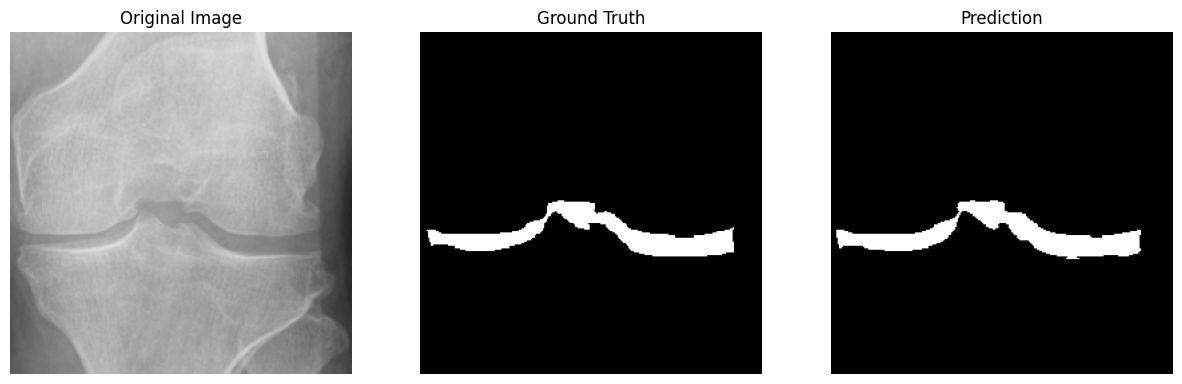

  1%|▏         | 1/80 [00:00<00:31,  2.50it/s]

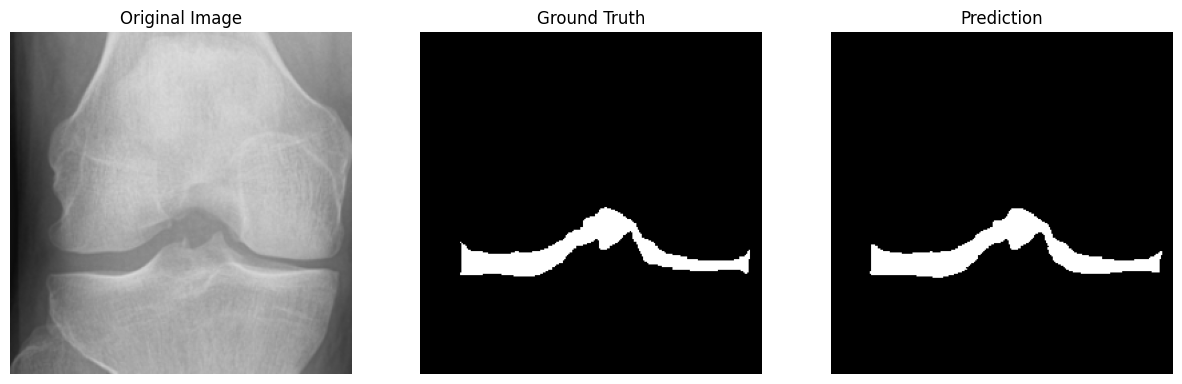

  2%|▎         | 2/80 [00:01<01:13,  1.06it/s]

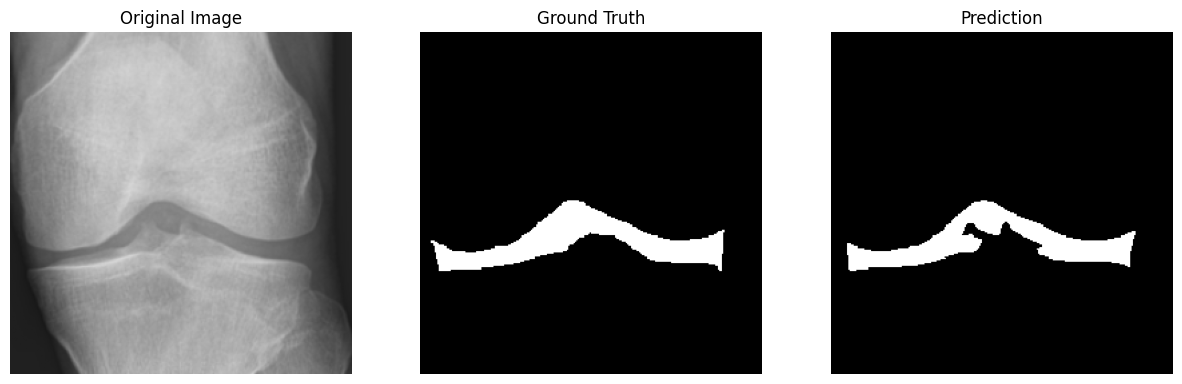

  4%|▍         | 3/80 [00:02<00:56,  1.37it/s]

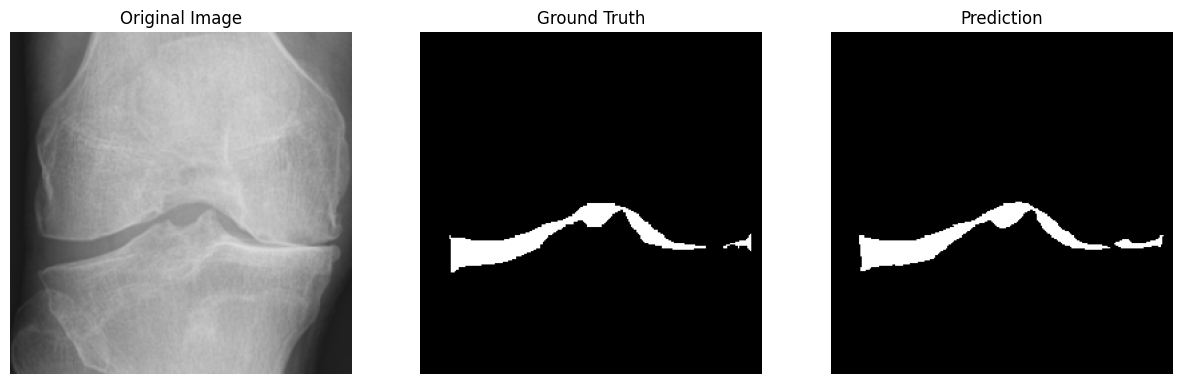

  5%|▌         | 4/80 [00:02<00:40,  1.87it/s]

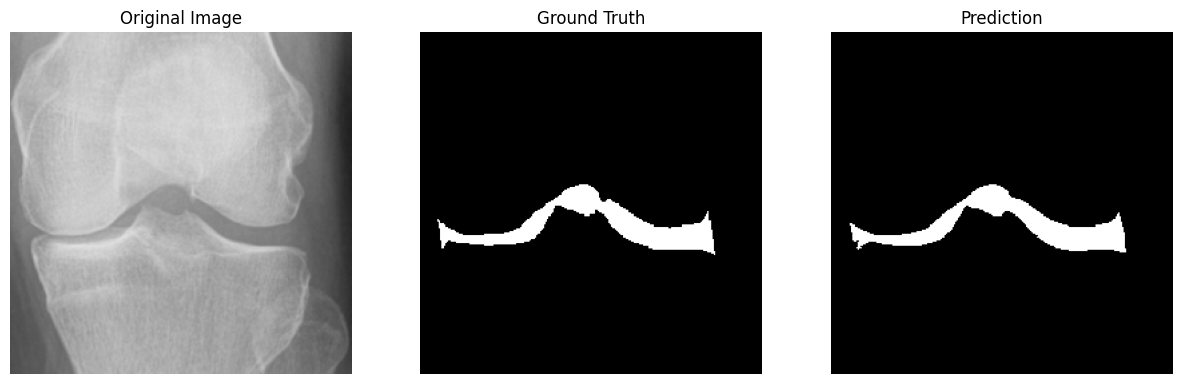

  6%|▋         | 5/80 [00:02<00:32,  2.34it/s]

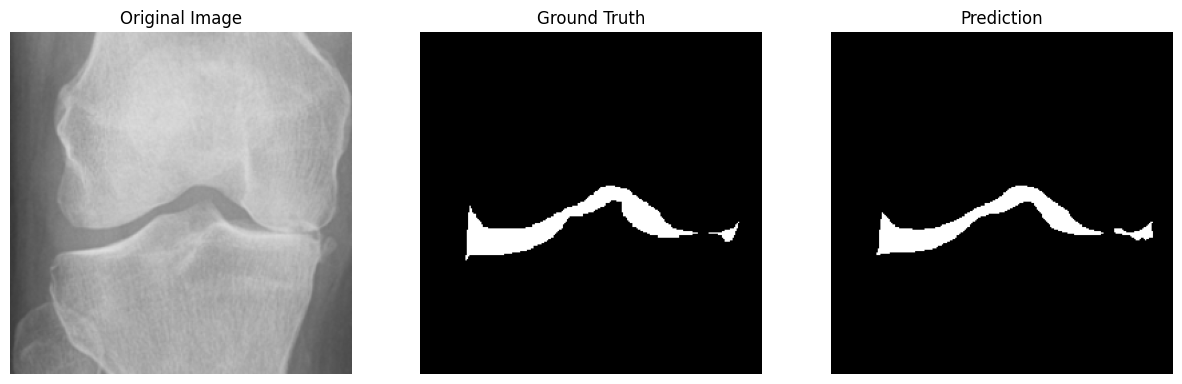

  8%|▊         | 6/80 [00:02<00:26,  2.75it/s]

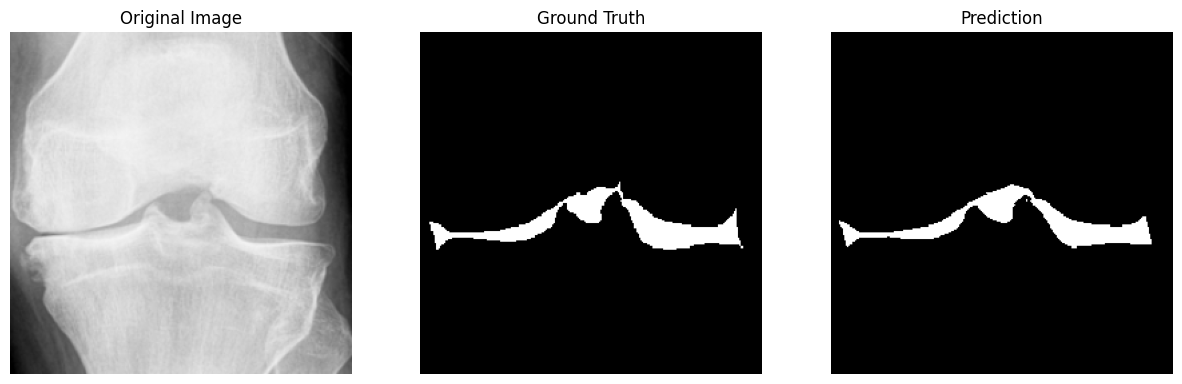

  9%|▉         | 7/80 [00:03<00:23,  3.06it/s]

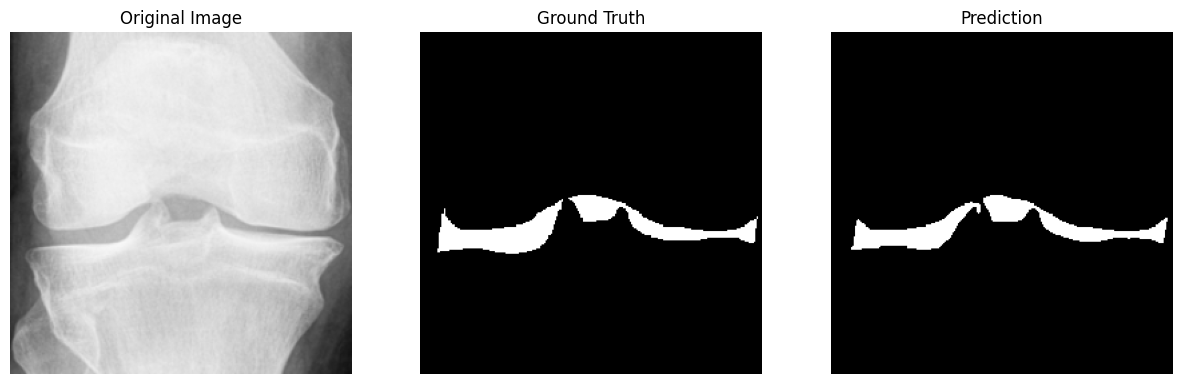

 10%|█         | 8/80 [00:03<00:21,  3.34it/s]

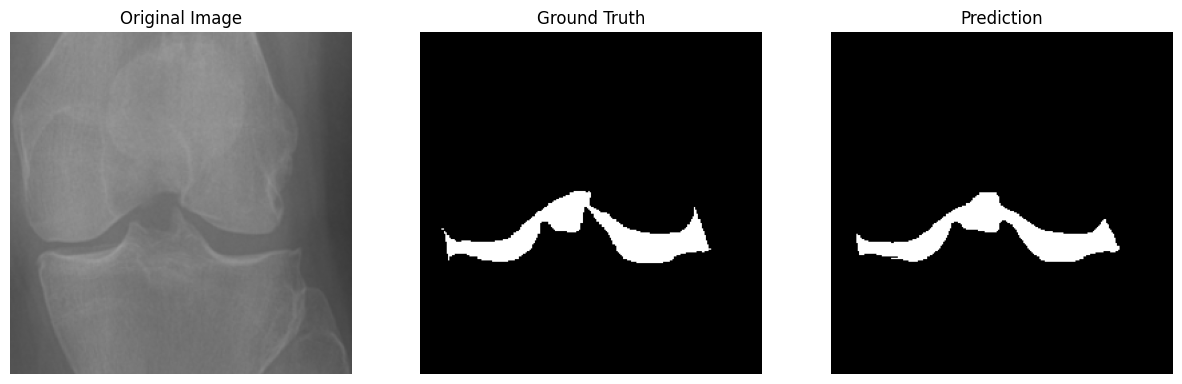

 11%|█▏        | 9/80 [00:03<00:20,  3.54it/s]

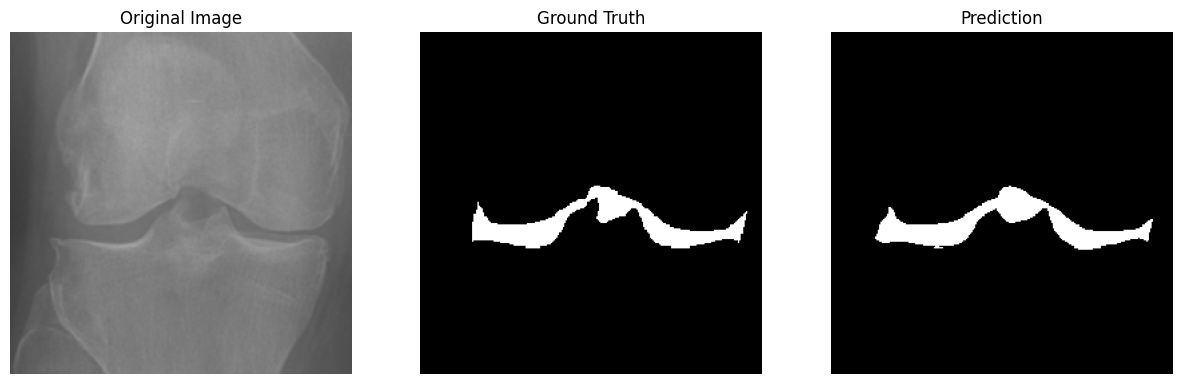

 12%|█▎        | 10/80 [00:03<00:18,  3.70it/s]

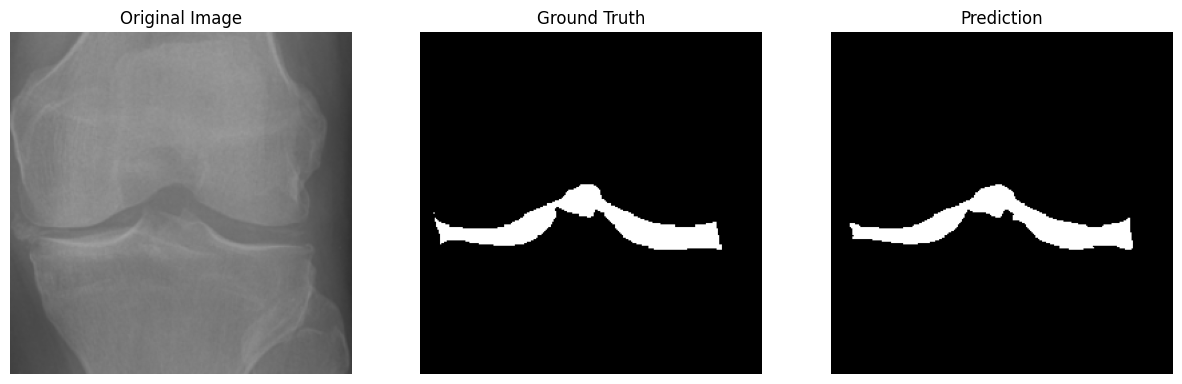

 14%|█▍        | 11/80 [00:04<00:18,  3.70it/s]

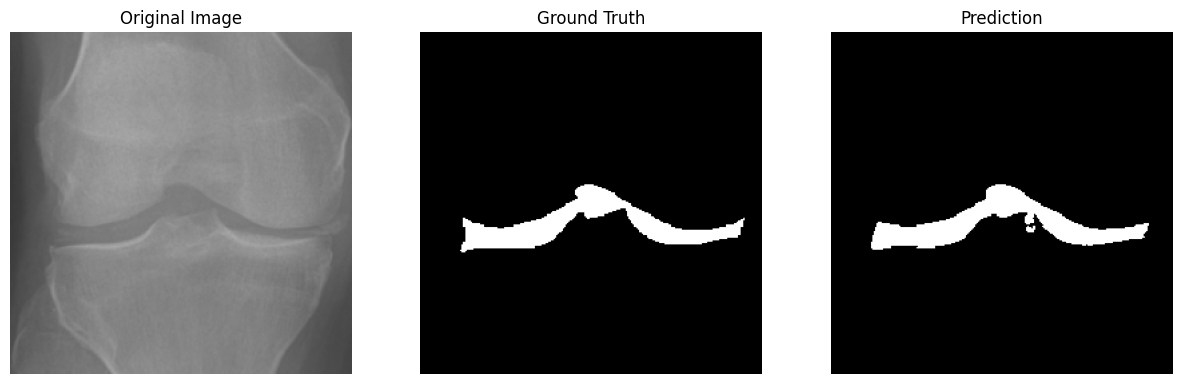

 15%|█▌        | 12/80 [00:04<00:20,  3.39it/s]

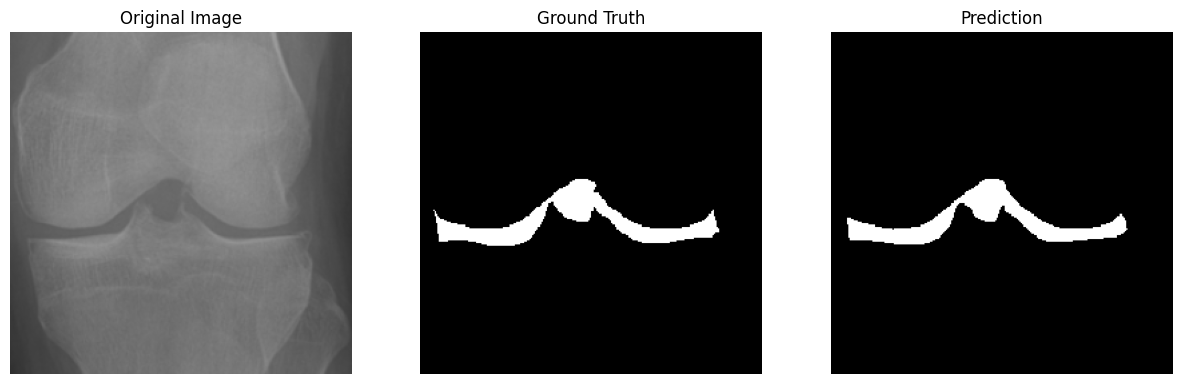

 16%|█▋        | 13/80 [00:04<00:21,  3.17it/s]

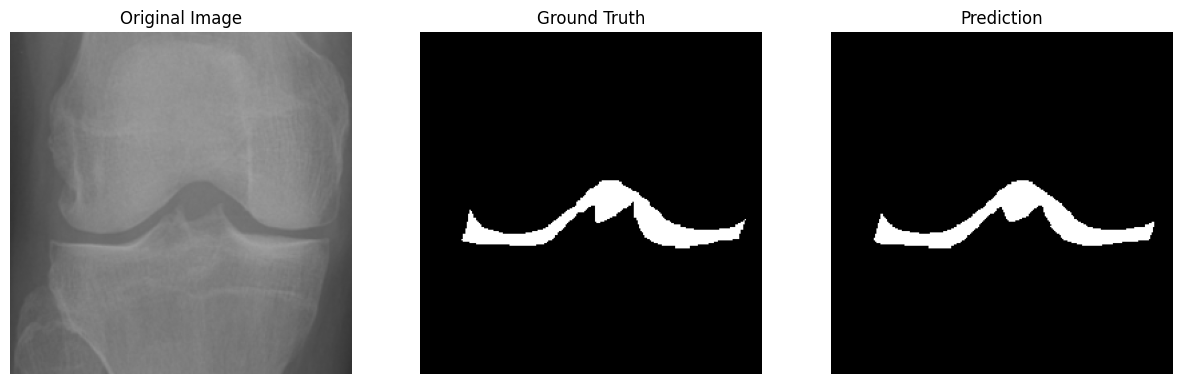

 18%|█▊        | 14/80 [00:05<00:21,  3.05it/s]

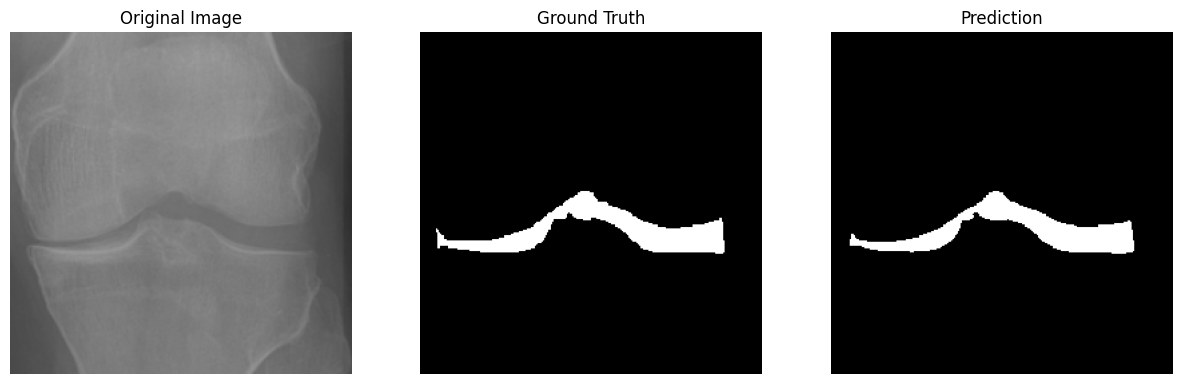

 19%|█▉        | 15/80 [00:05<00:21,  3.01it/s]

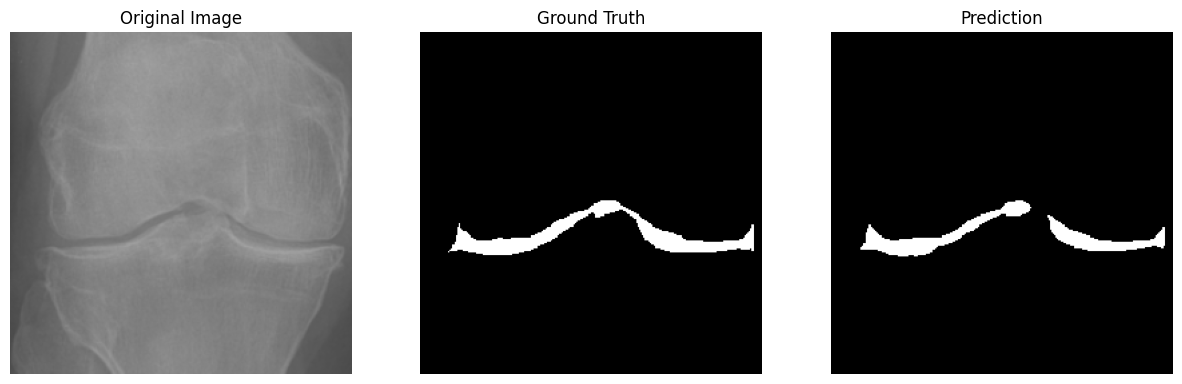

 20%|██        | 16/80 [00:05<00:22,  2.90it/s]

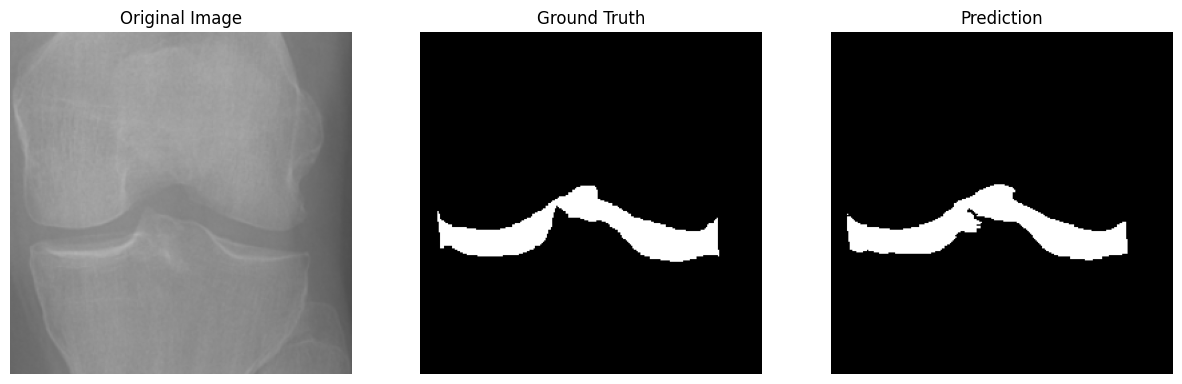

 21%|██▏       | 17/80 [00:06<00:21,  2.87it/s]

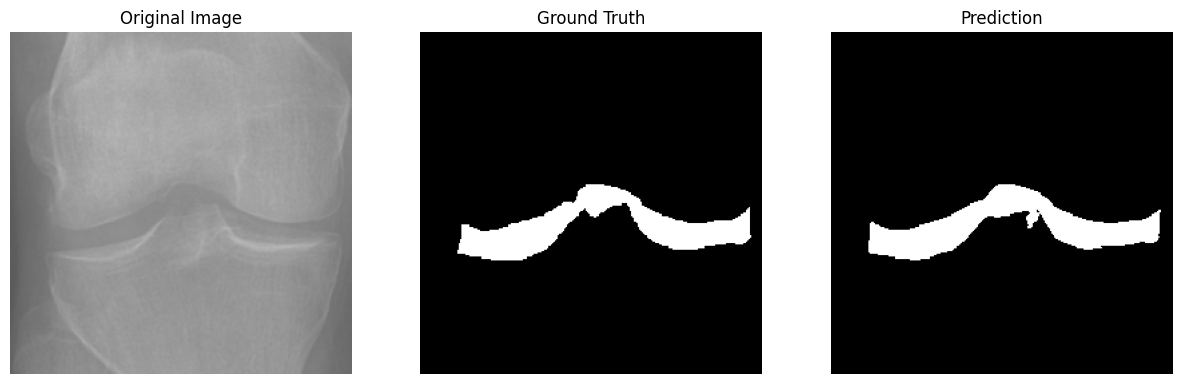

 22%|██▎       | 18/80 [00:06<00:21,  2.88it/s]

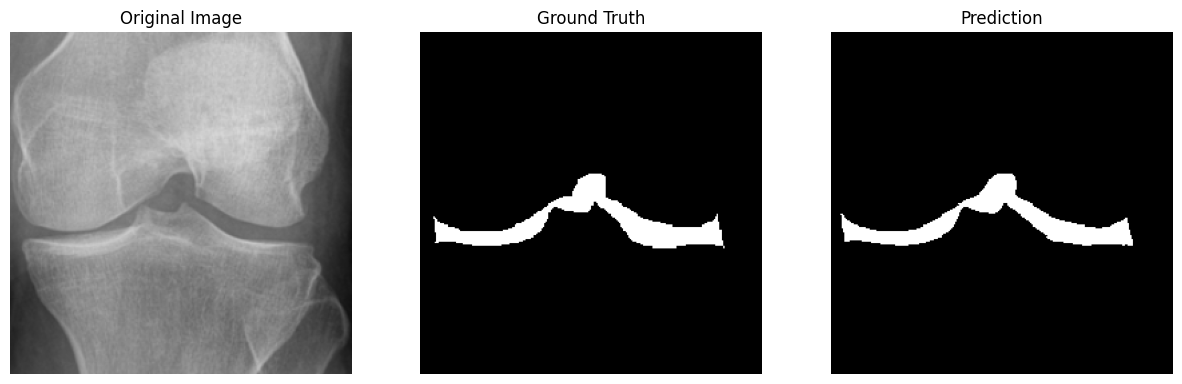

 24%|██▍       | 19/80 [00:07<00:21,  2.85it/s]

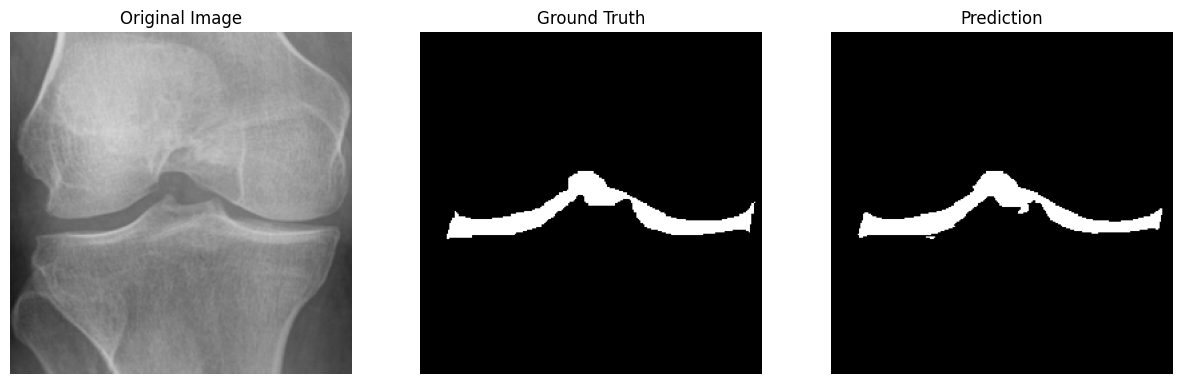

 25%|██▌       | 20/80 [00:07<00:21,  2.79it/s]

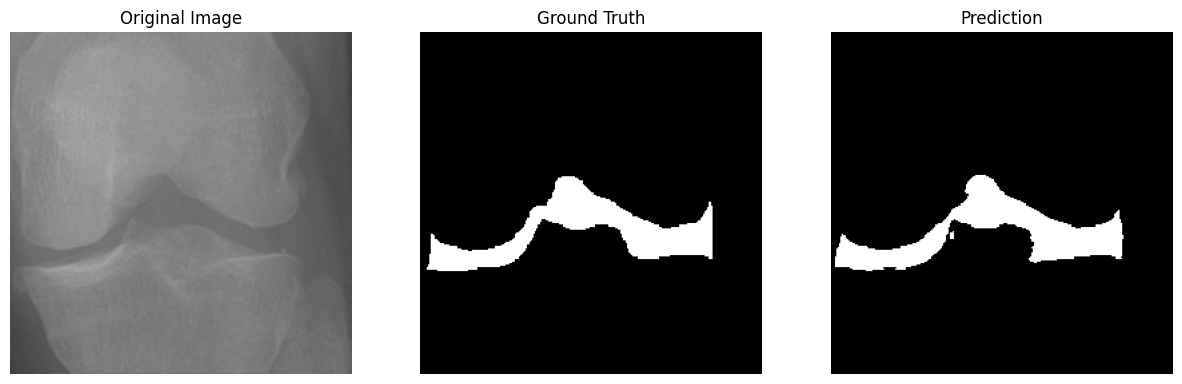

 26%|██▋       | 21/80 [00:07<00:21,  2.76it/s]

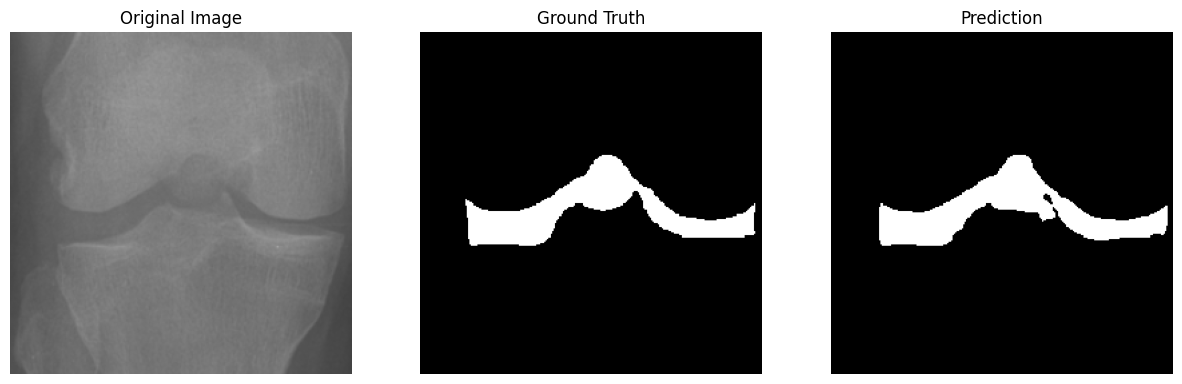

 28%|██▊       | 22/80 [00:08<00:20,  2.87it/s]

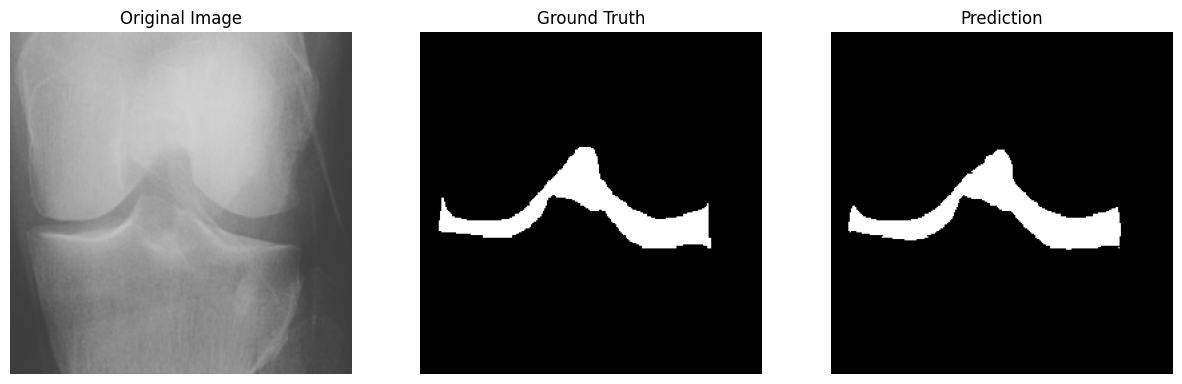

 29%|██▉       | 23/80 [00:08<00:18,  3.10it/s]

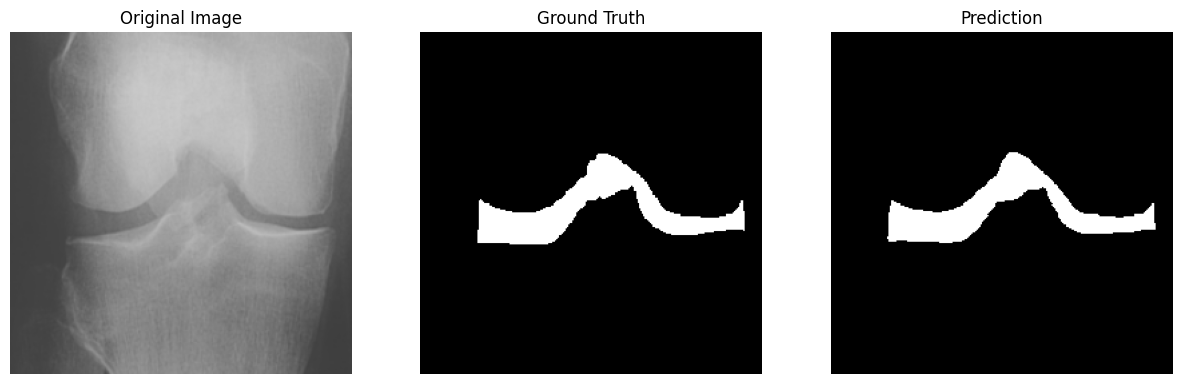

 30%|███       | 24/80 [00:08<00:16,  3.33it/s]

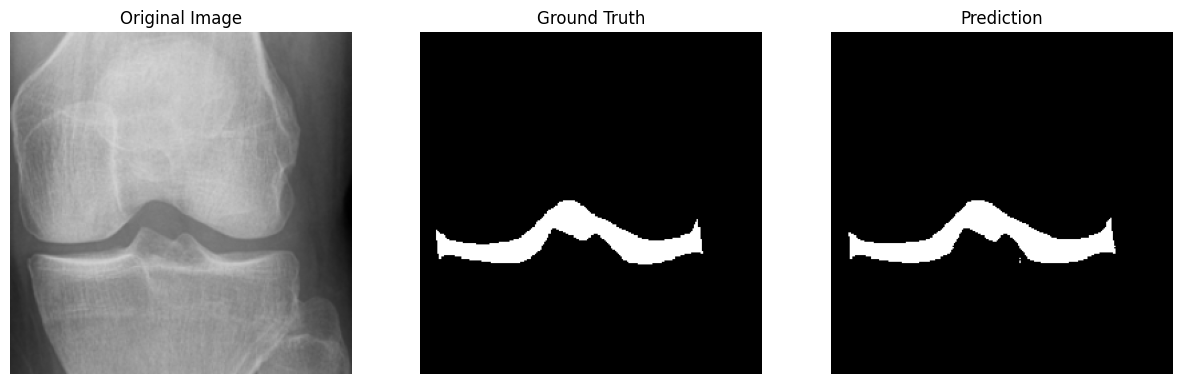

 31%|███▏      | 25/80 [00:08<00:15,  3.49it/s]

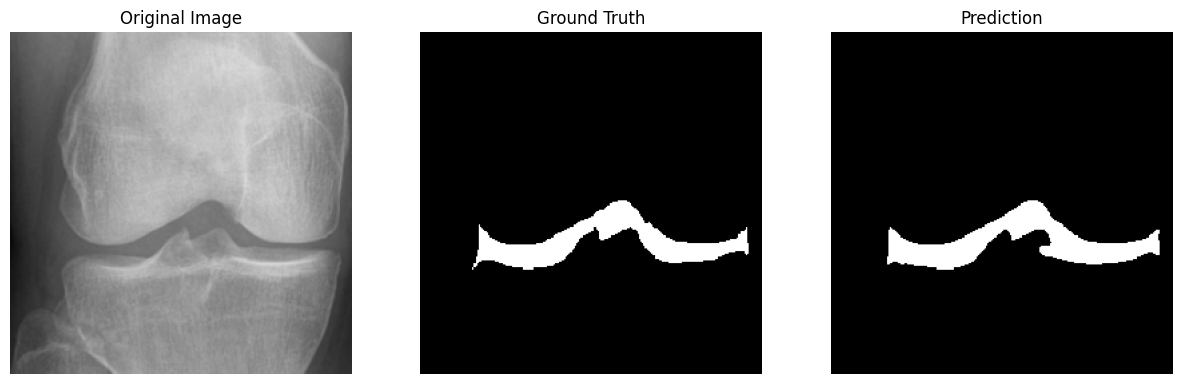

 32%|███▎      | 26/80 [00:09<00:14,  3.61it/s]

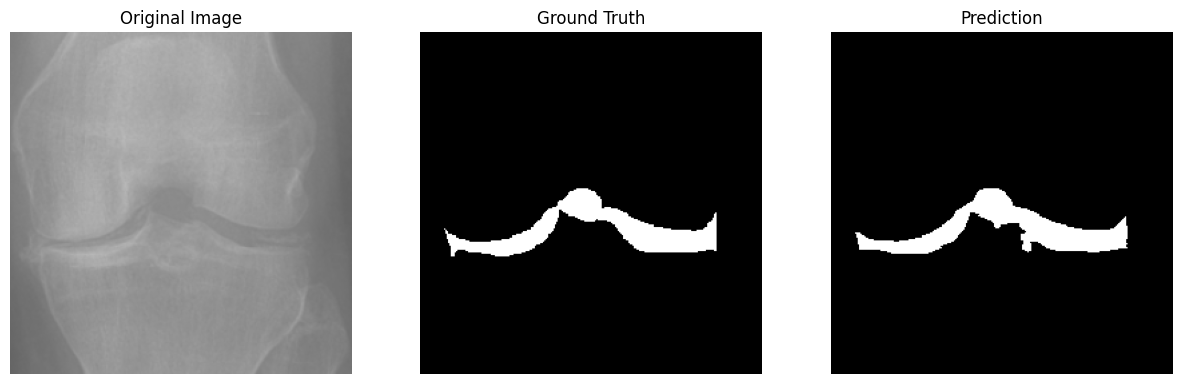

 34%|███▍      | 27/80 [00:09<00:14,  3.66it/s]

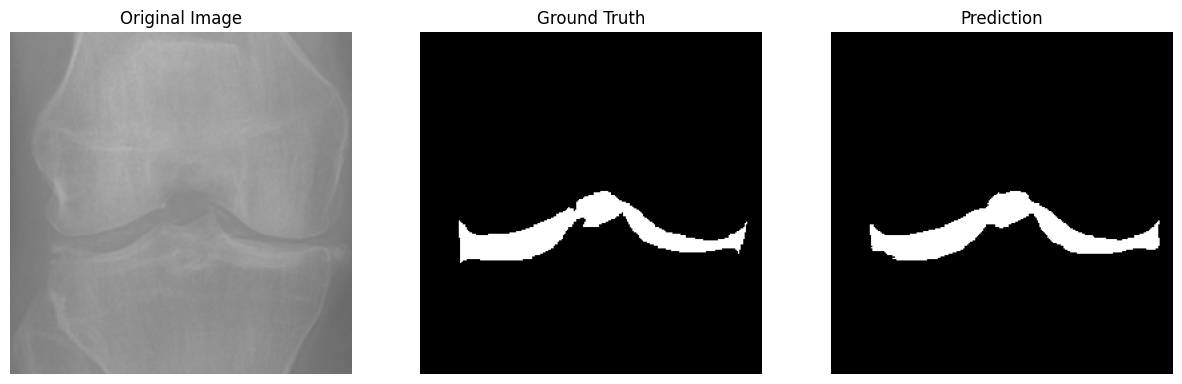

 35%|███▌      | 28/80 [00:09<00:13,  3.74it/s]

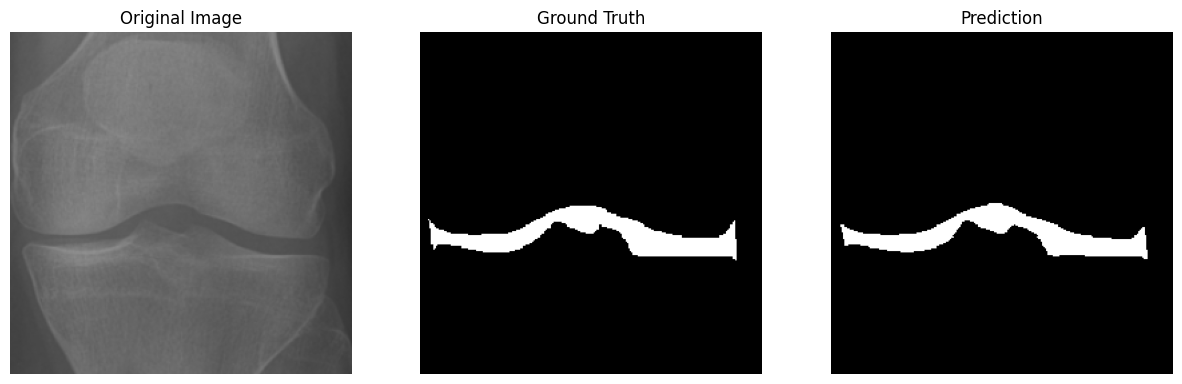

 36%|███▋      | 29/80 [00:09<00:13,  3.79it/s]

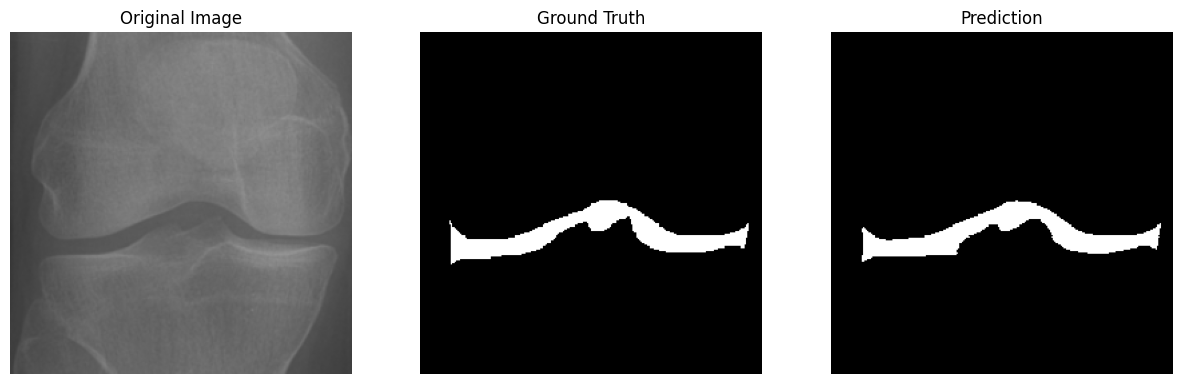

 38%|███▊      | 30/80 [00:10<00:13,  3.81it/s]

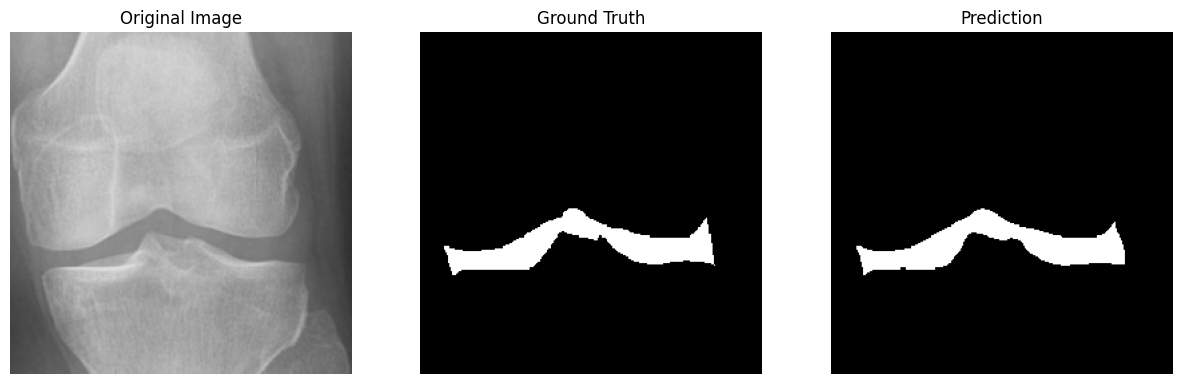

 39%|███▉      | 31/80 [00:10<00:13,  3.77it/s]

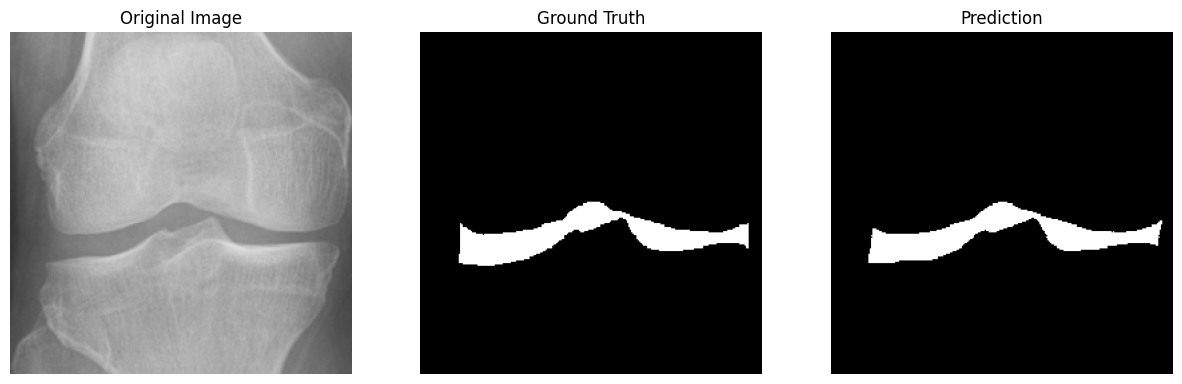

 40%|████      | 32/80 [00:10<00:12,  3.79it/s]

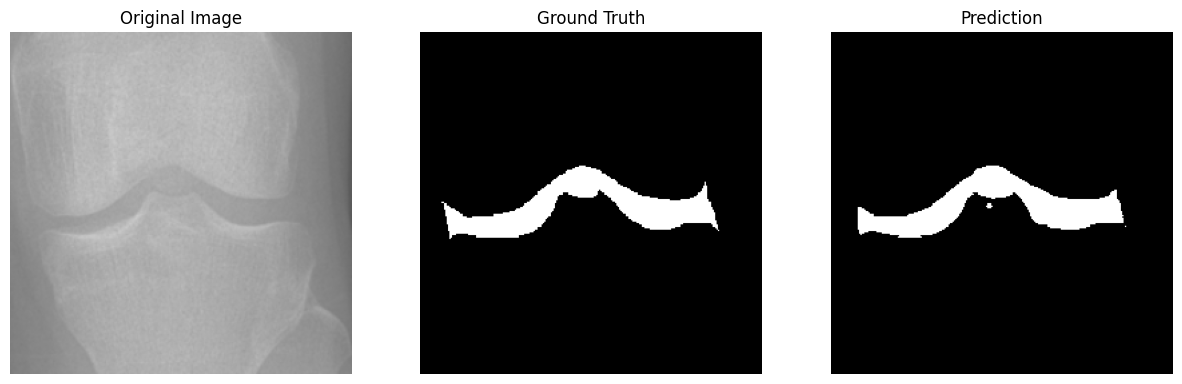

 41%|████▏     | 33/80 [00:10<00:12,  3.70it/s]

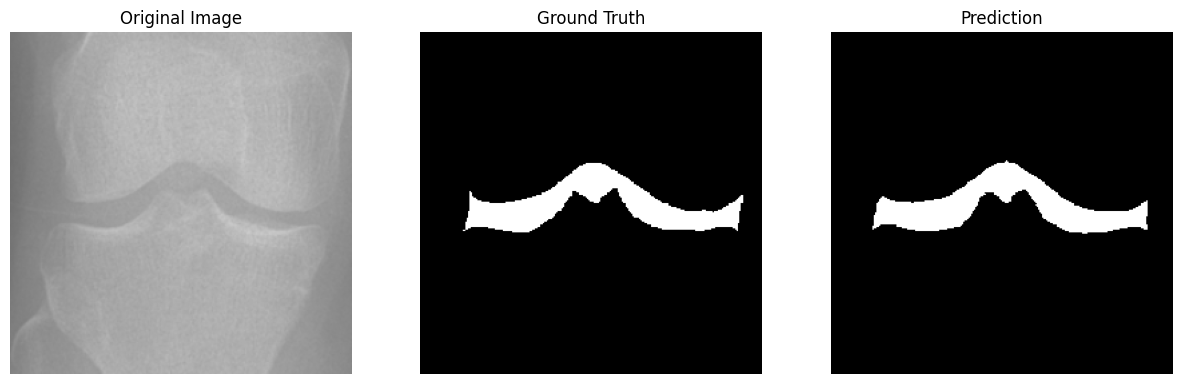

 42%|████▎     | 34/80 [00:11<00:18,  2.43it/s]

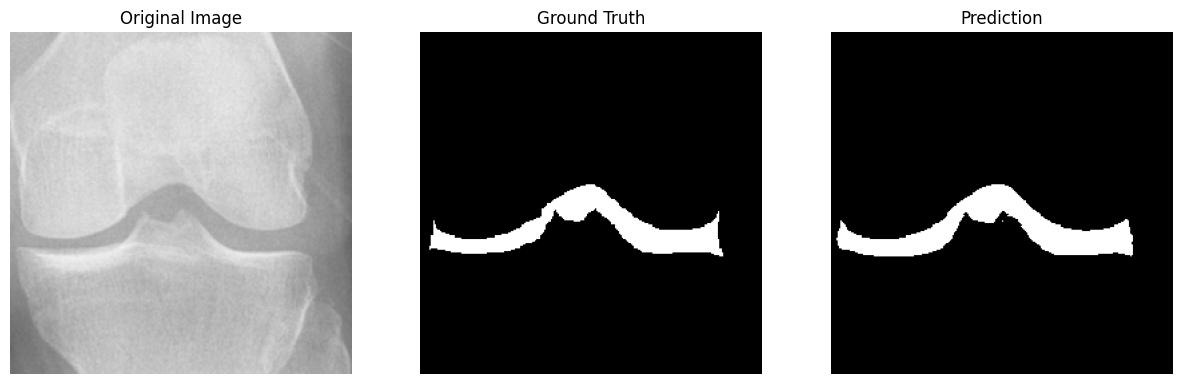

 44%|████▍     | 35/80 [00:11<00:16,  2.67it/s]

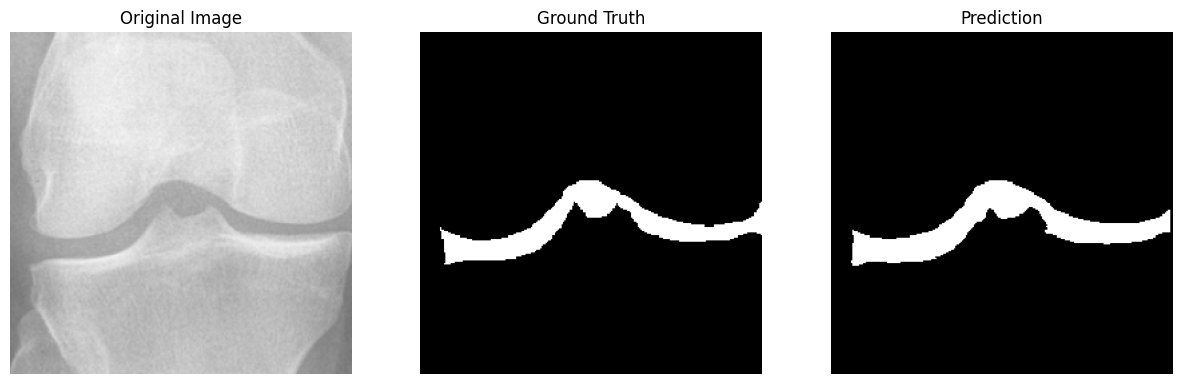

 45%|████▌     | 36/80 [00:12<00:15,  2.91it/s]

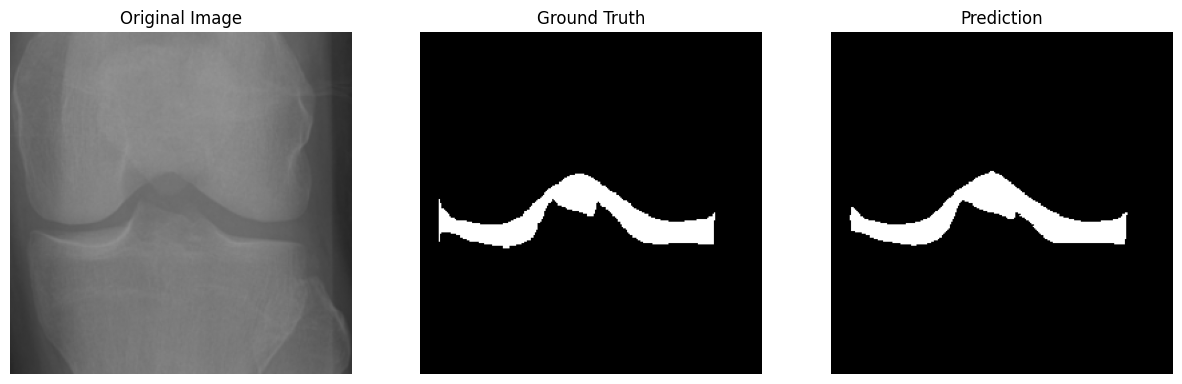

 46%|████▋     | 37/80 [00:12<00:13,  3.08it/s]

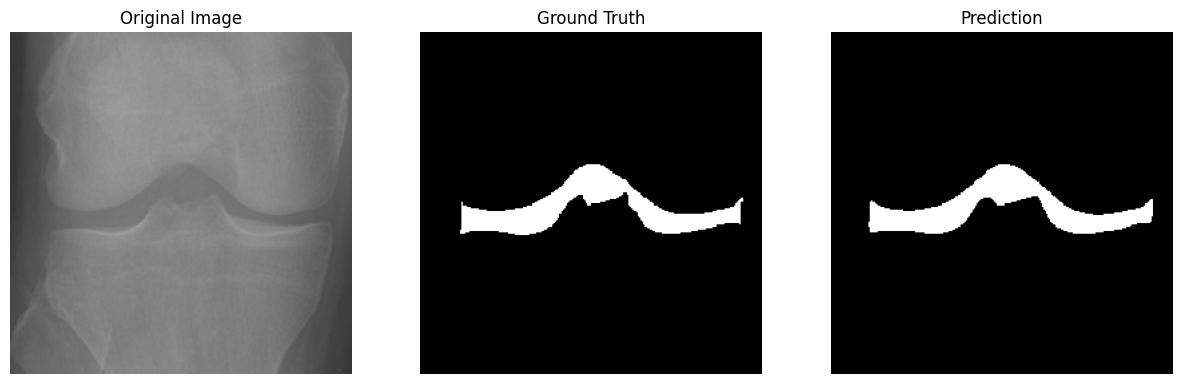

 48%|████▊     | 38/80 [00:12<00:12,  3.27it/s]

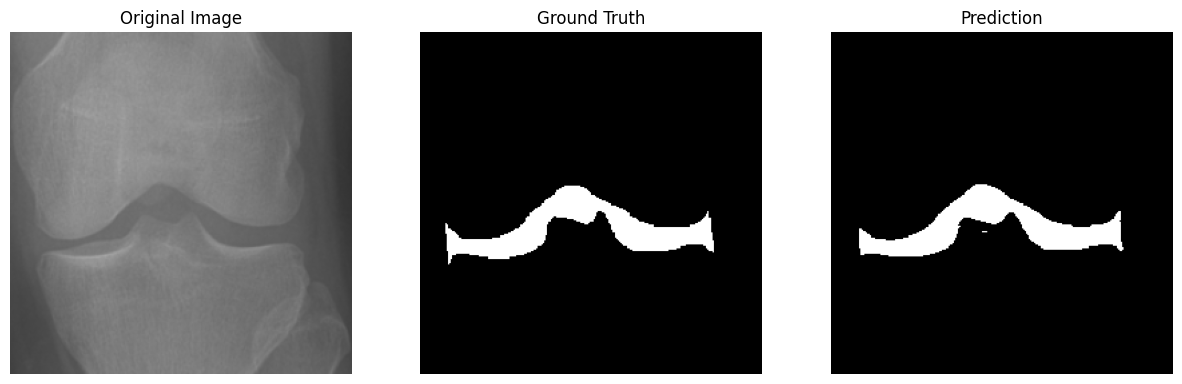

 49%|████▉     | 39/80 [00:13<00:12,  3.36it/s]

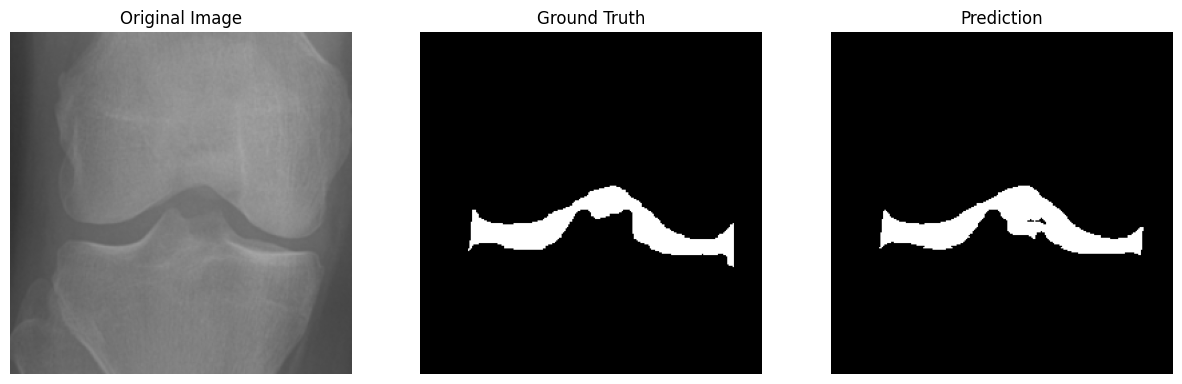

 50%|█████     | 40/80 [00:13<00:11,  3.48it/s]

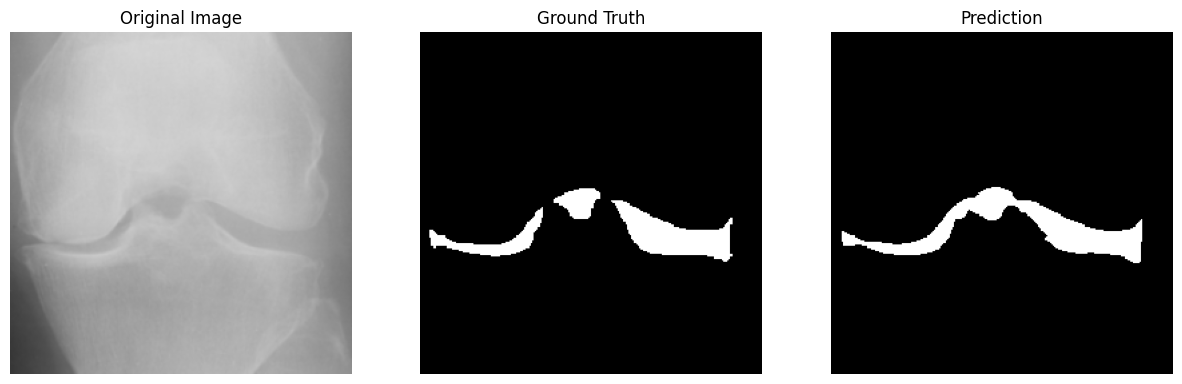

 51%|█████▏    | 41/80 [00:13<00:11,  3.51it/s]

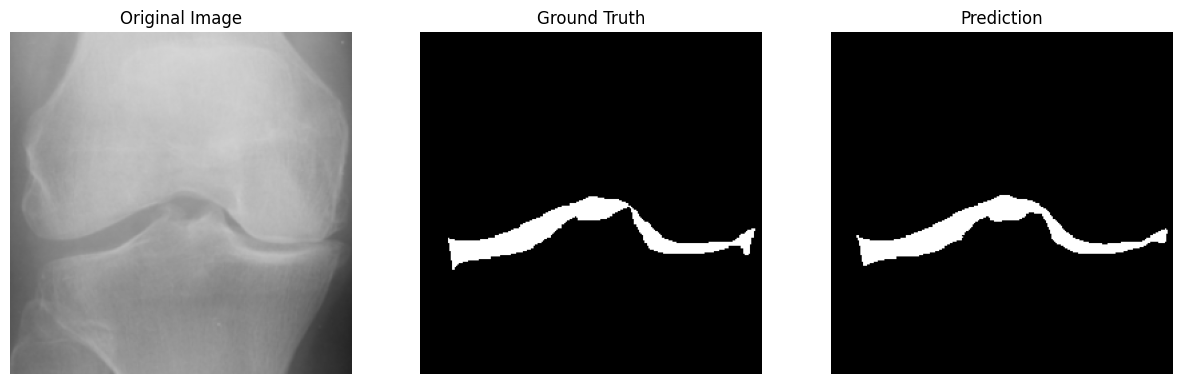

 52%|█████▎    | 42/80 [00:13<00:10,  3.60it/s]

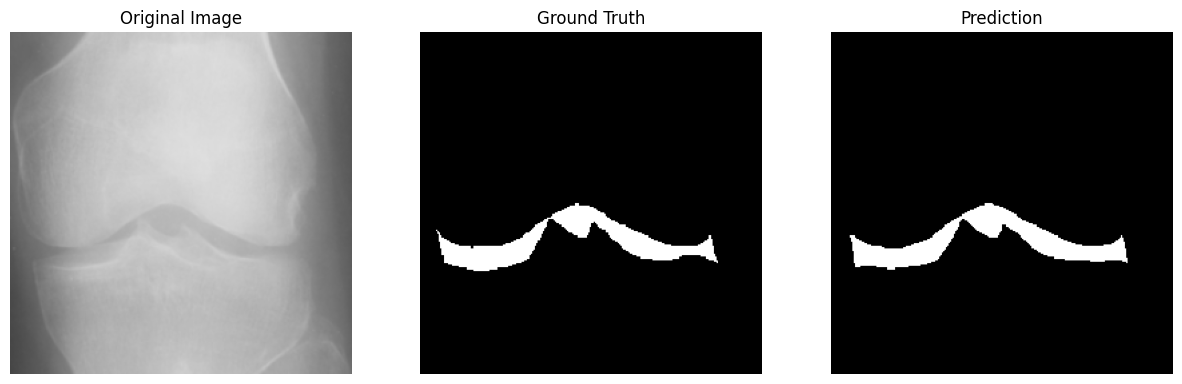

 54%|█████▍    | 43/80 [00:14<00:10,  3.65it/s]

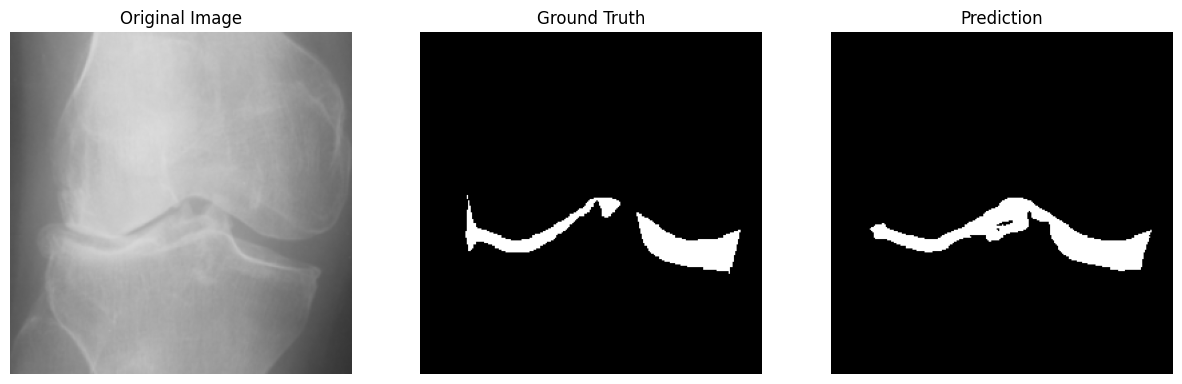

 55%|█████▌    | 44/80 [00:14<00:09,  3.69it/s]

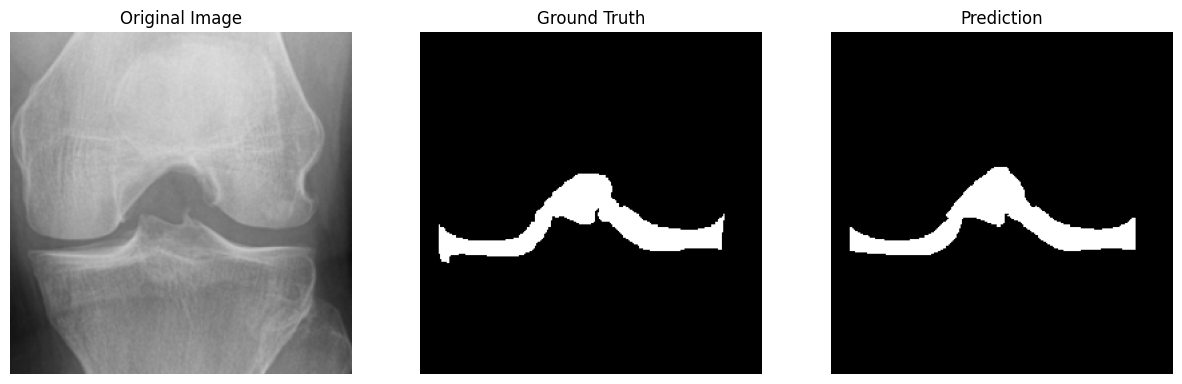

 56%|█████▋    | 45/80 [00:14<00:09,  3.64it/s]

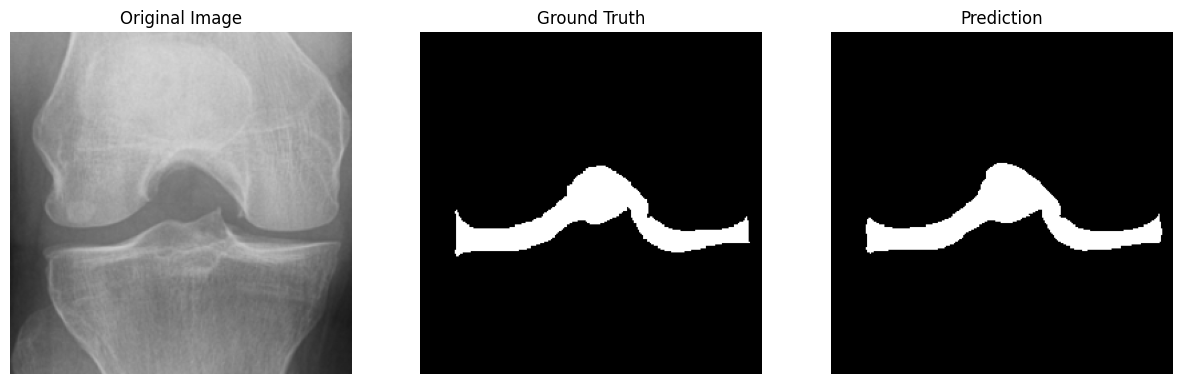

 57%|█████▊    | 46/80 [00:14<00:09,  3.65it/s]

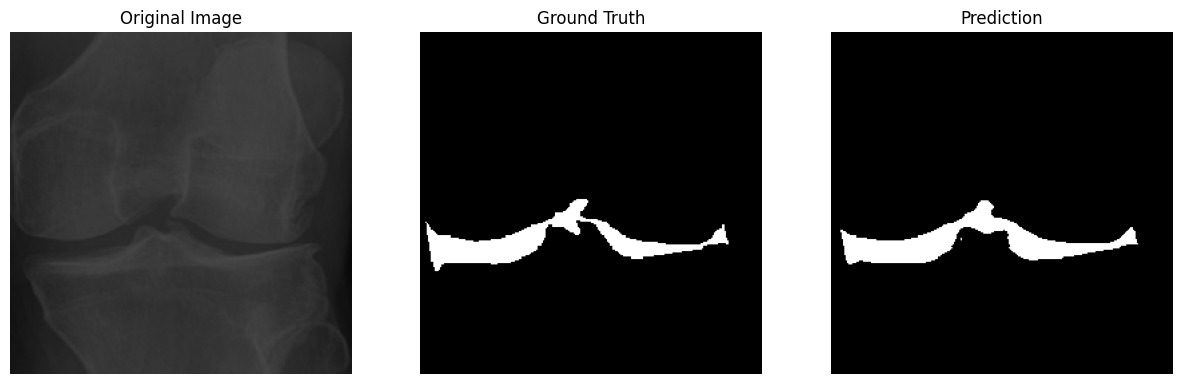

 59%|█████▉    | 47/80 [00:15<00:08,  3.67it/s]

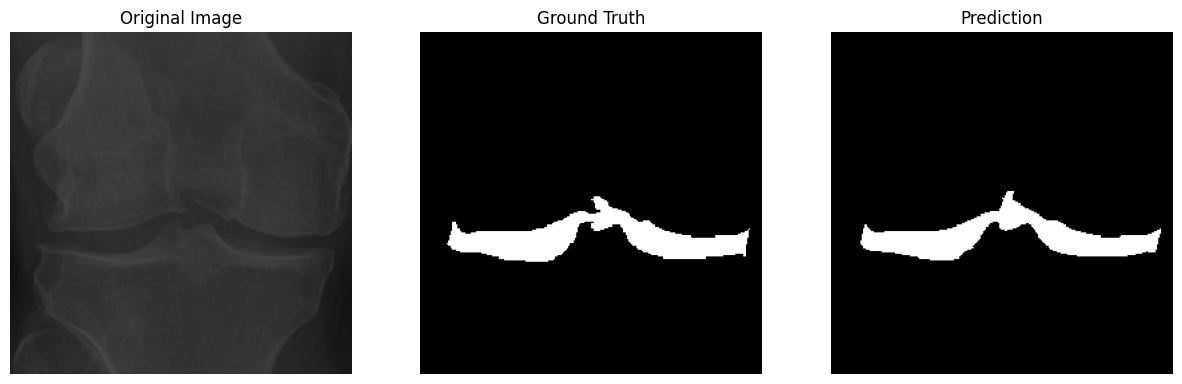

 60%|██████    | 48/80 [00:15<00:08,  3.69it/s]

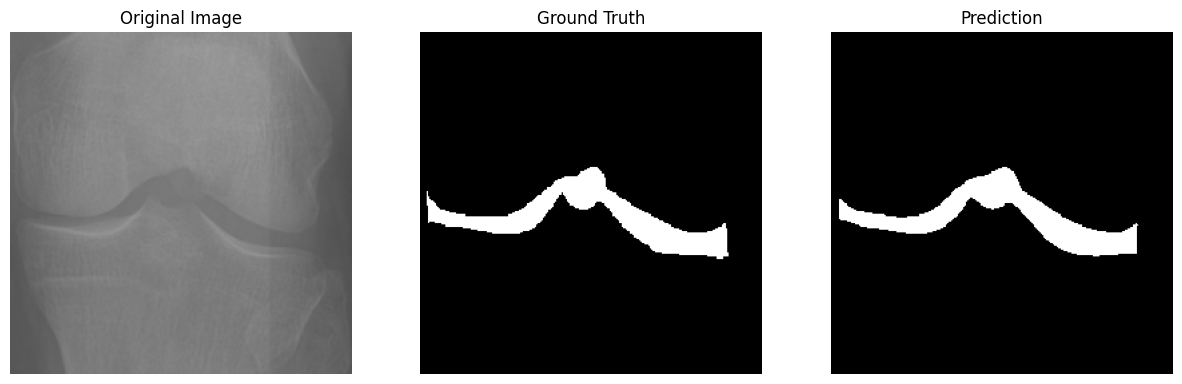

 61%|██████▏   | 49/80 [00:15<00:08,  3.61it/s]

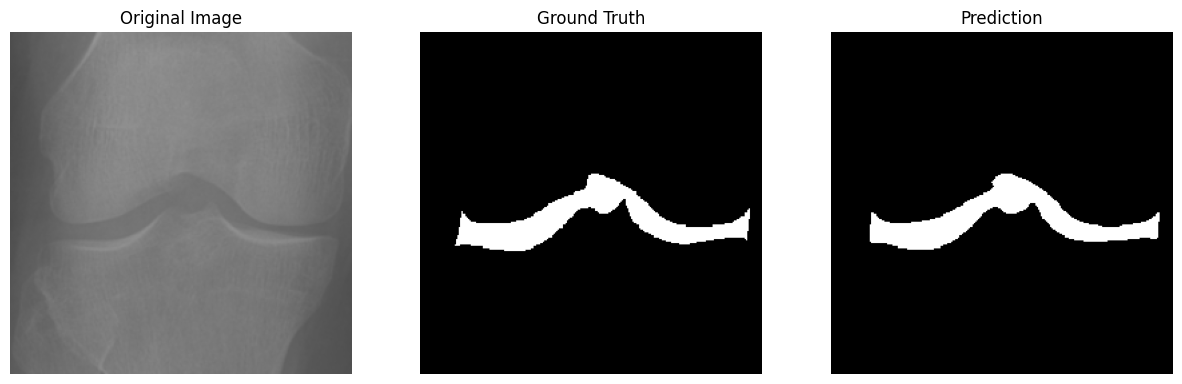

 62%|██████▎   | 50/80 [00:16<00:08,  3.63it/s]

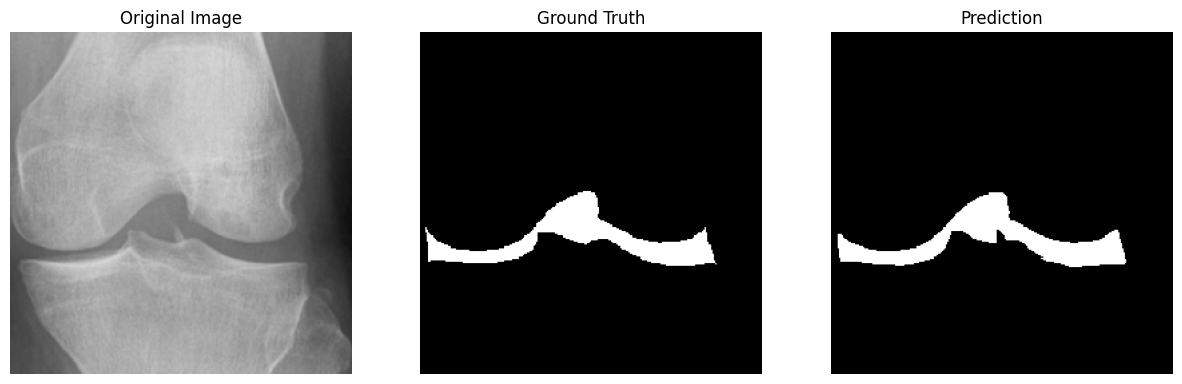

 64%|██████▍   | 51/80 [00:16<00:07,  3.64it/s]

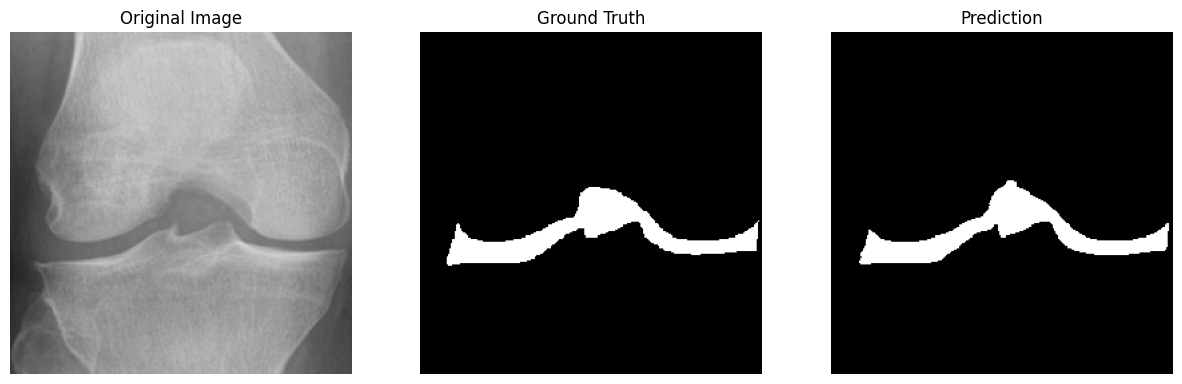

 65%|██████▌   | 52/80 [00:16<00:07,  3.63it/s]

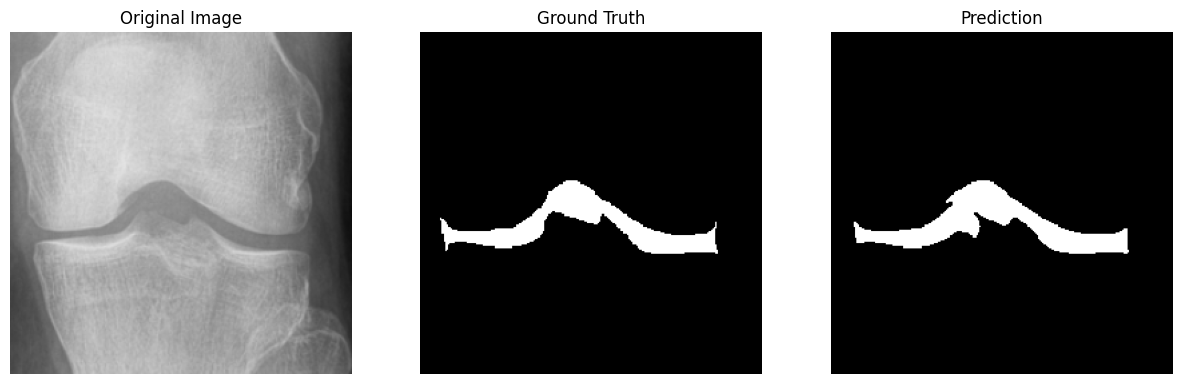

 66%|██████▋   | 53/80 [00:16<00:07,  3.49it/s]

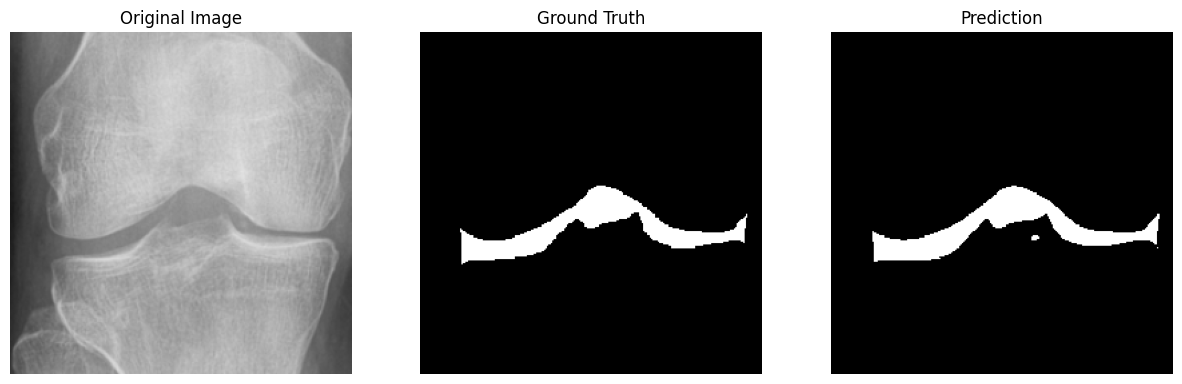

 68%|██████▊   | 54/80 [00:17<00:07,  3.49it/s]

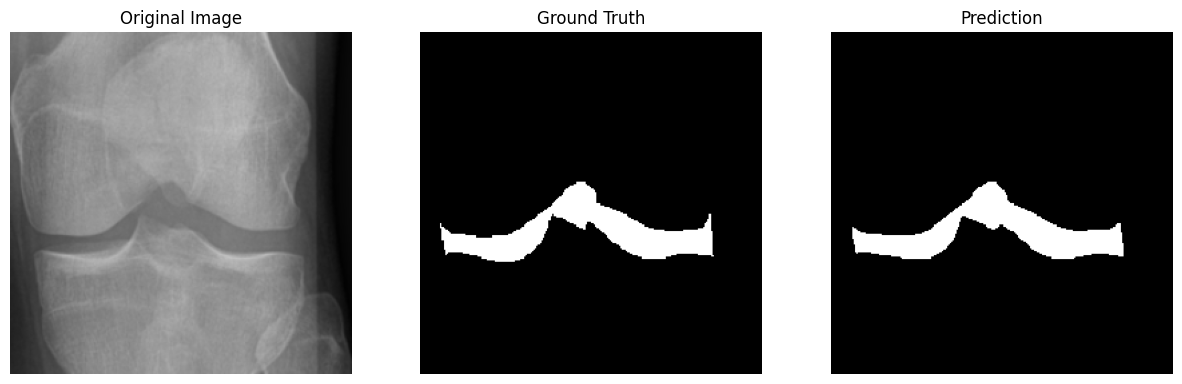

 69%|██████▉   | 55/80 [00:17<00:07,  3.50it/s]

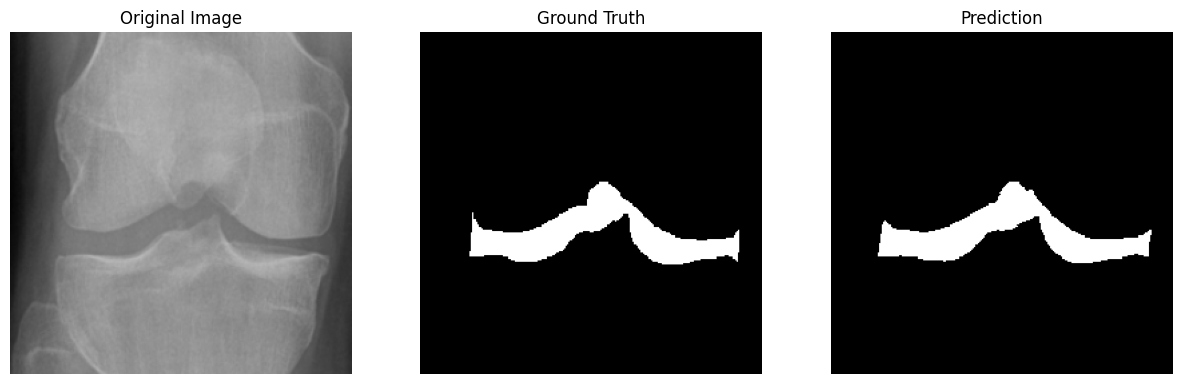

 70%|███████   | 56/80 [00:17<00:07,  3.38it/s]

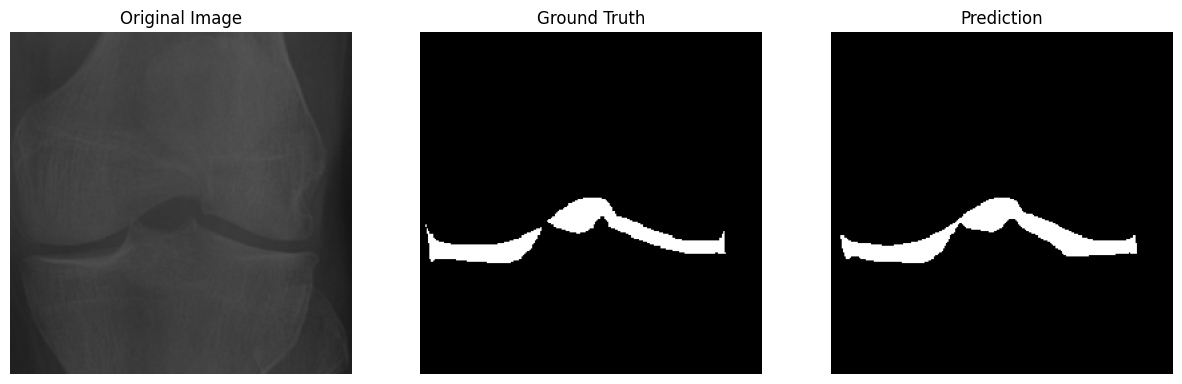

 71%|███████▏  | 57/80 [00:18<00:07,  3.21it/s]

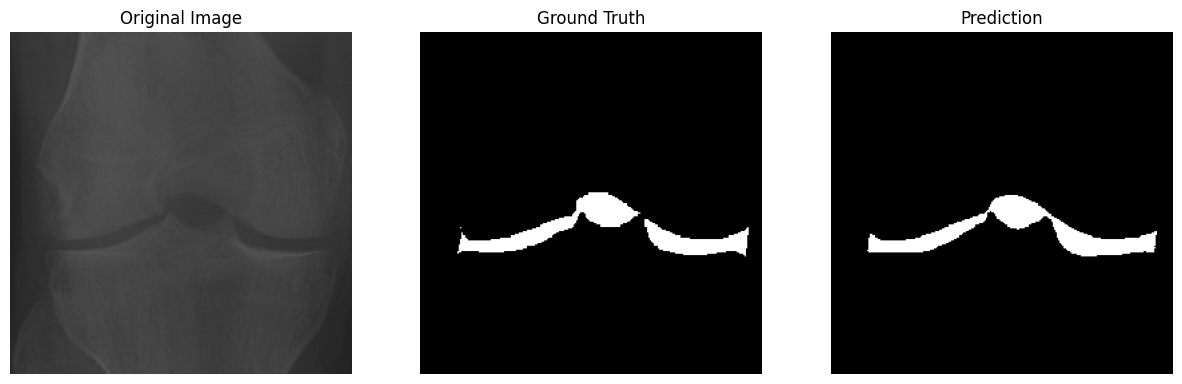

 72%|███████▎  | 58/80 [00:18<00:07,  3.08it/s]

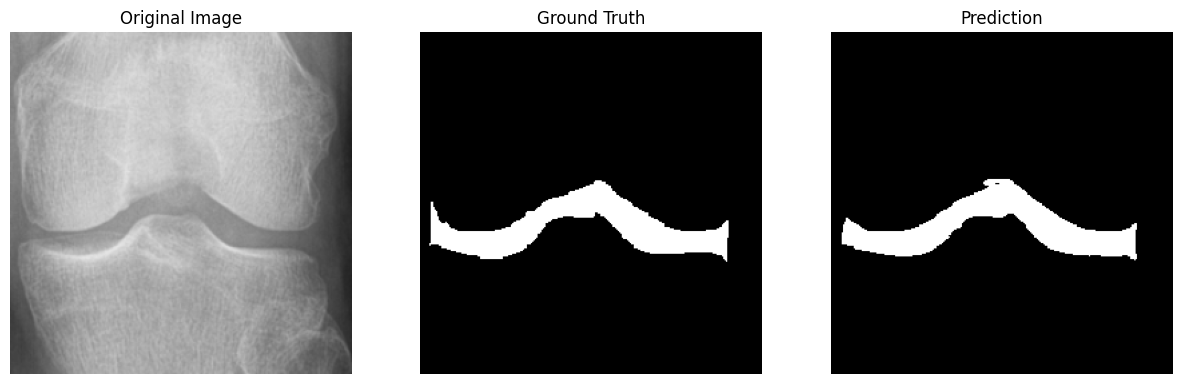

 74%|███████▍  | 59/80 [00:18<00:07,  2.96it/s]

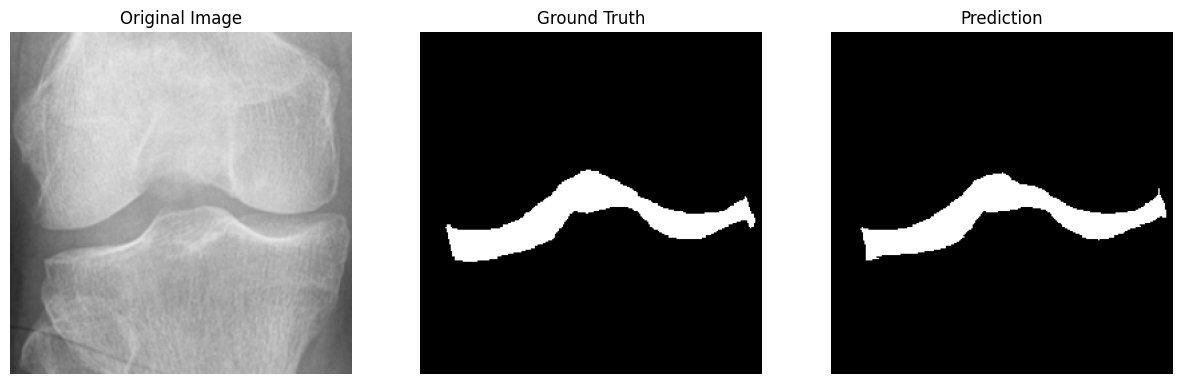

 75%|███████▌  | 60/80 [00:19<00:06,  2.96it/s]

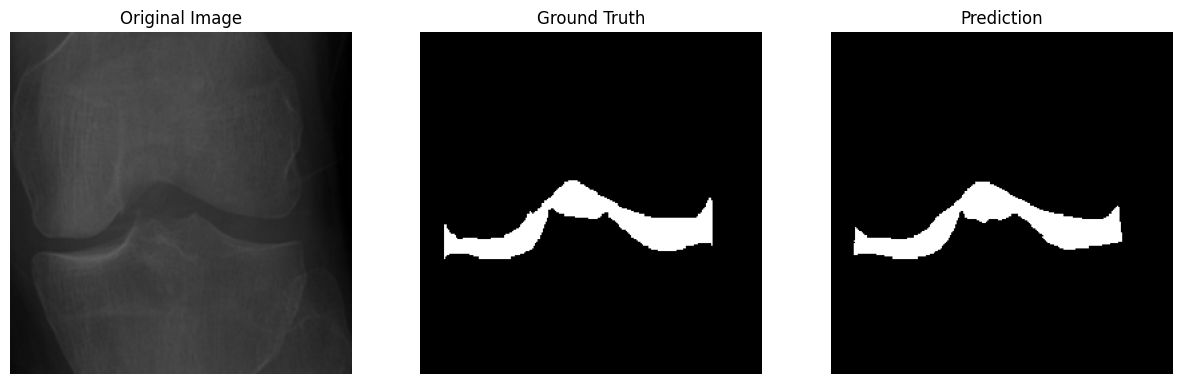

 76%|███████▋  | 61/80 [00:19<00:06,  2.95it/s]

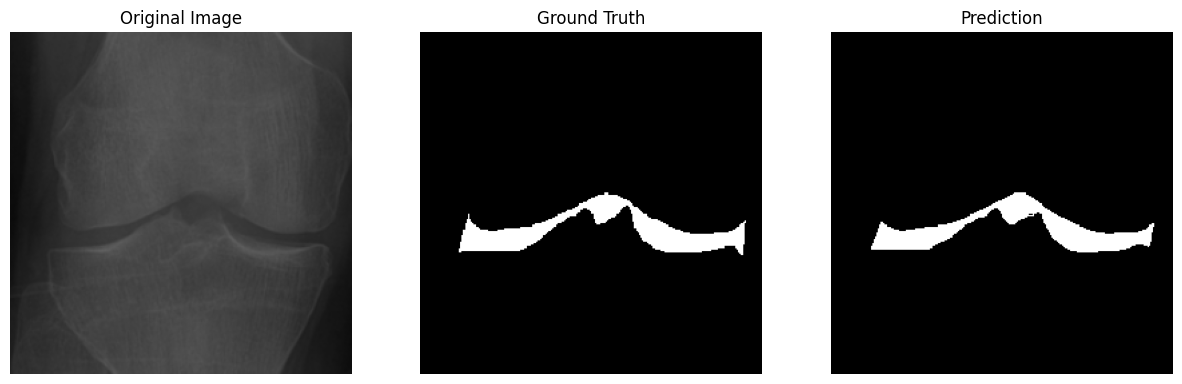

 78%|███████▊  | 62/80 [00:19<00:06,  2.85it/s]

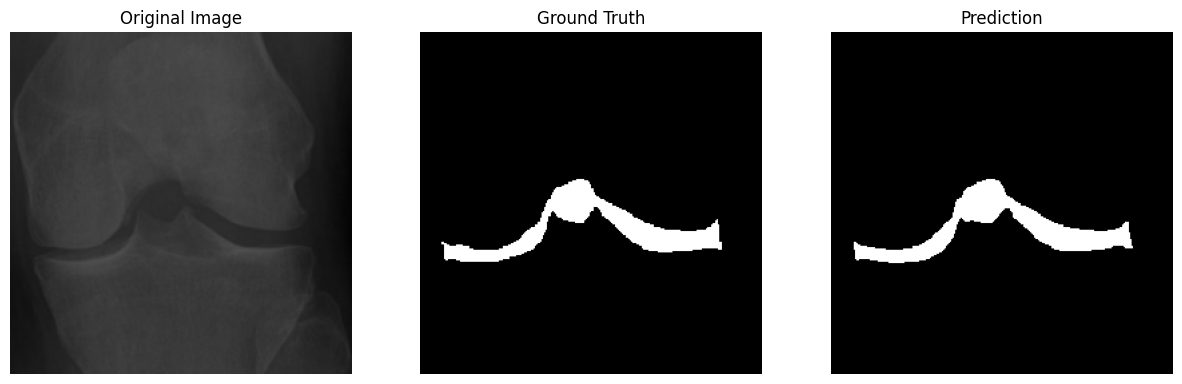

 79%|███████▉  | 63/80 [00:20<00:05,  2.85it/s]

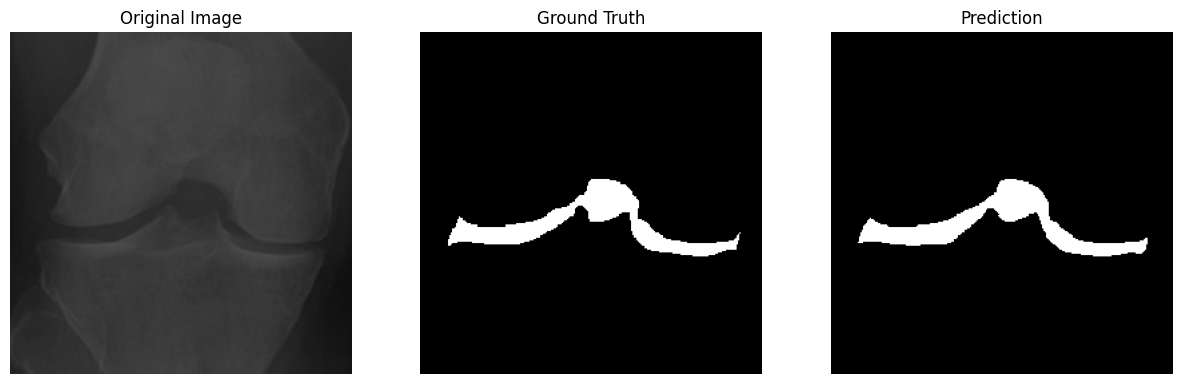

 80%|████████  | 64/80 [00:20<00:05,  2.80it/s]

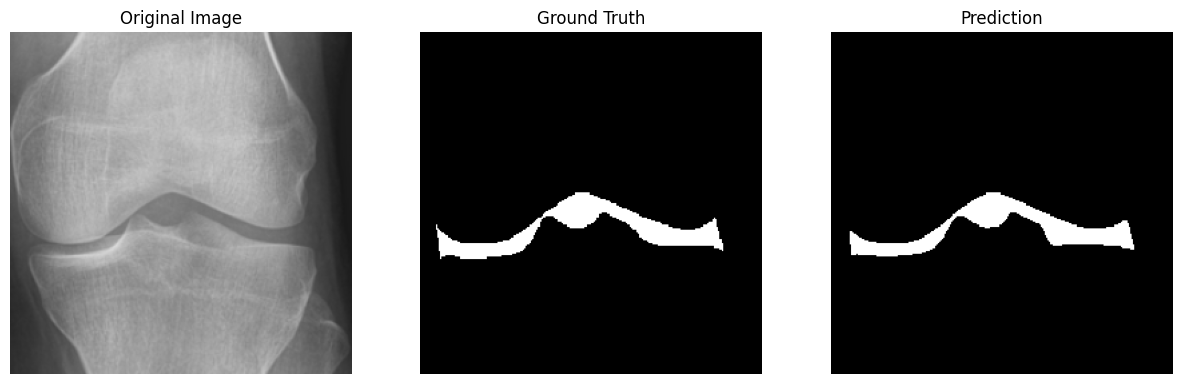

 81%|████████▏ | 65/80 [00:20<00:05,  2.86it/s]

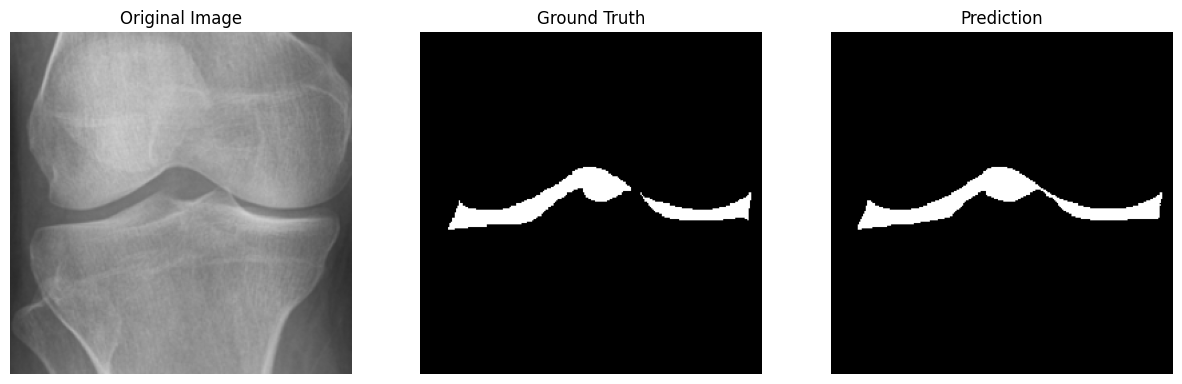

 82%|████████▎ | 66/80 [00:21<00:04,  2.83it/s]

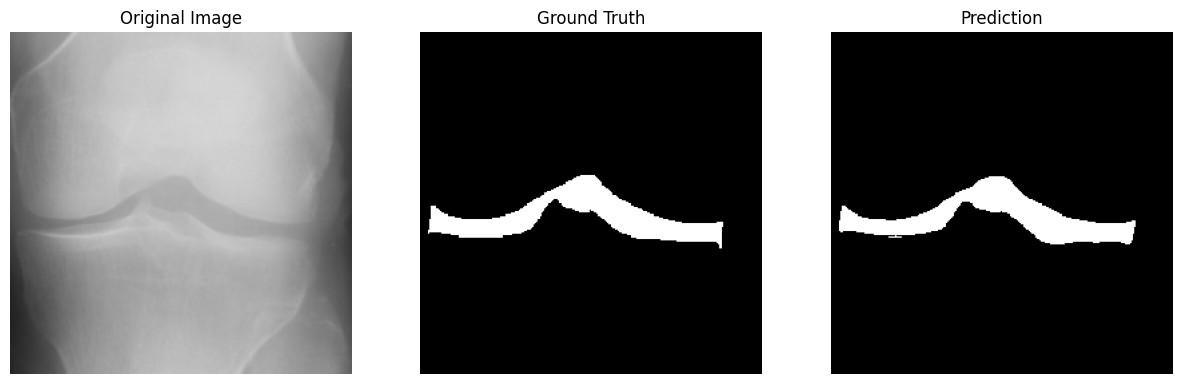

 84%|████████▍ | 67/80 [00:22<00:07,  1.83it/s]

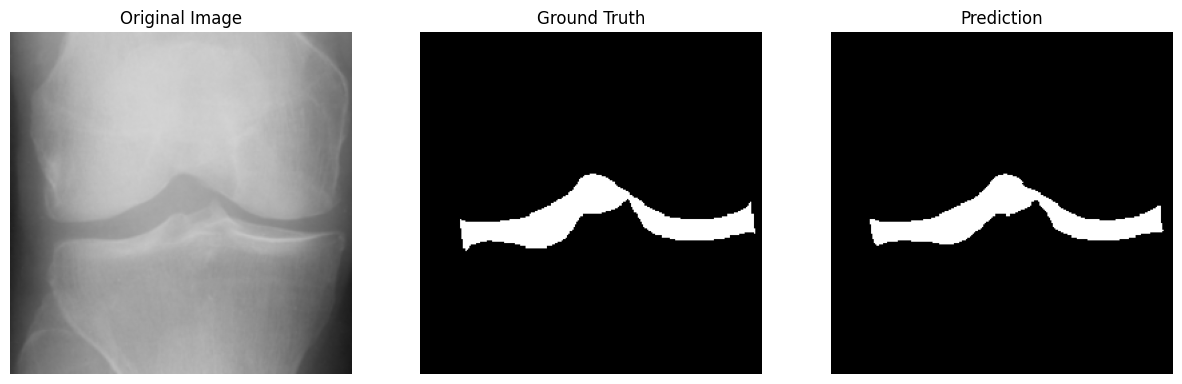

 85%|████████▌ | 68/80 [00:22<00:05,  2.04it/s]

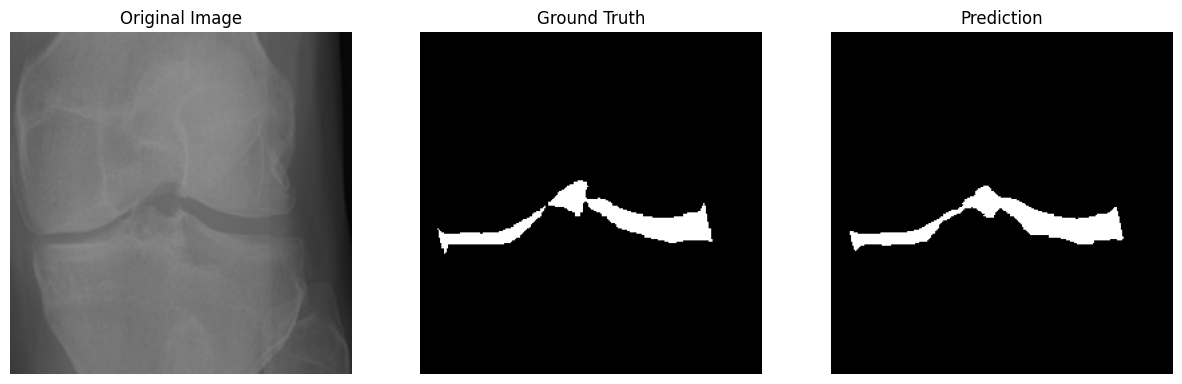

 86%|████████▋ | 69/80 [00:23<00:05,  2.18it/s]

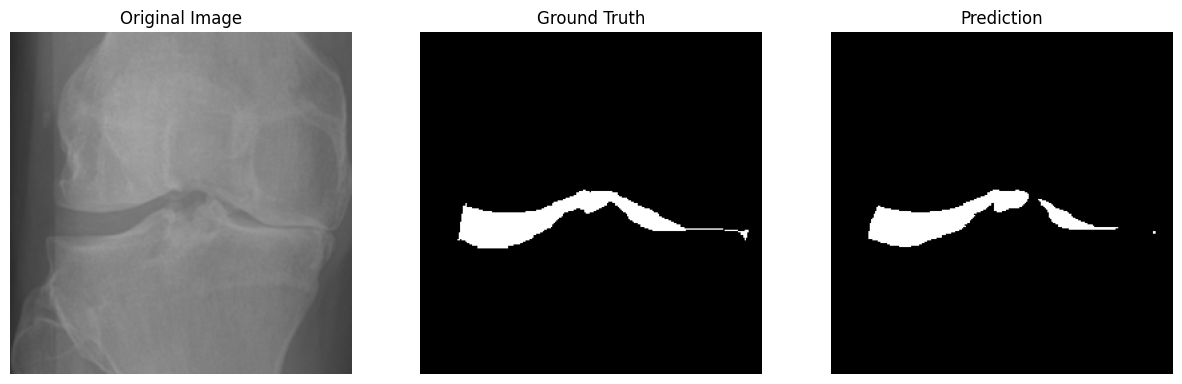

 88%|████████▊ | 70/80 [00:23<00:04,  2.26it/s]

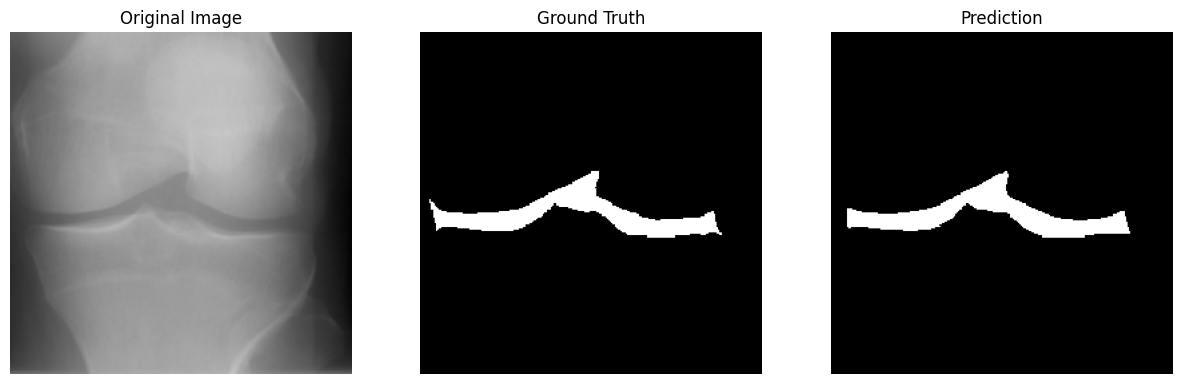

 89%|████████▉ | 71/80 [00:23<00:03,  2.51it/s]

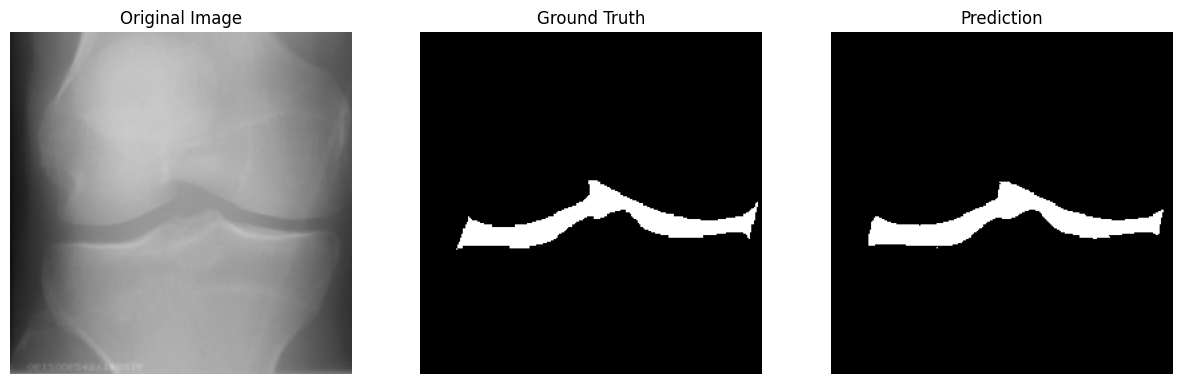

 90%|█████████ | 72/80 [00:24<00:02,  2.73it/s]

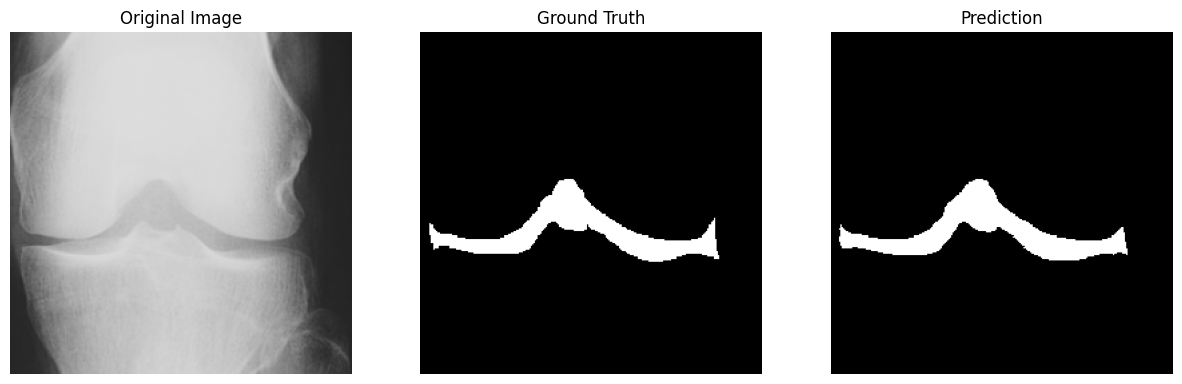

 91%|█████████▏| 73/80 [00:24<00:02,  2.86it/s]

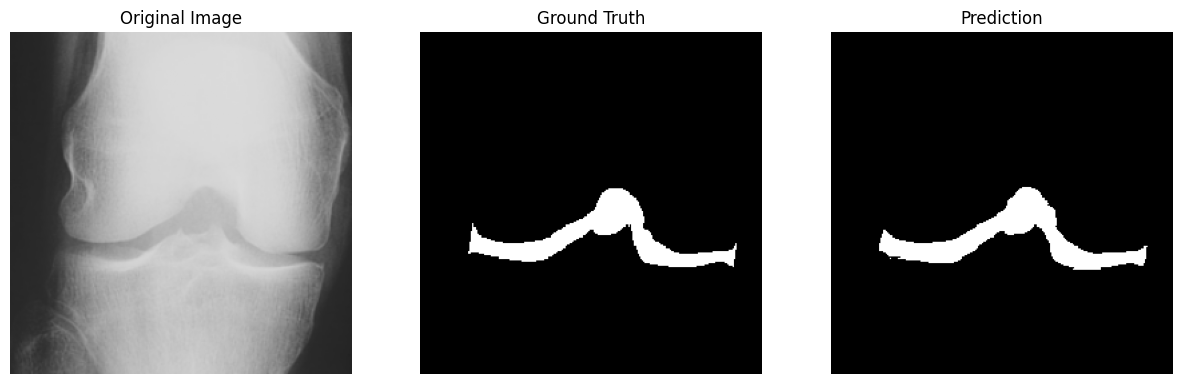

 92%|█████████▎| 74/80 [00:24<00:01,  3.01it/s]

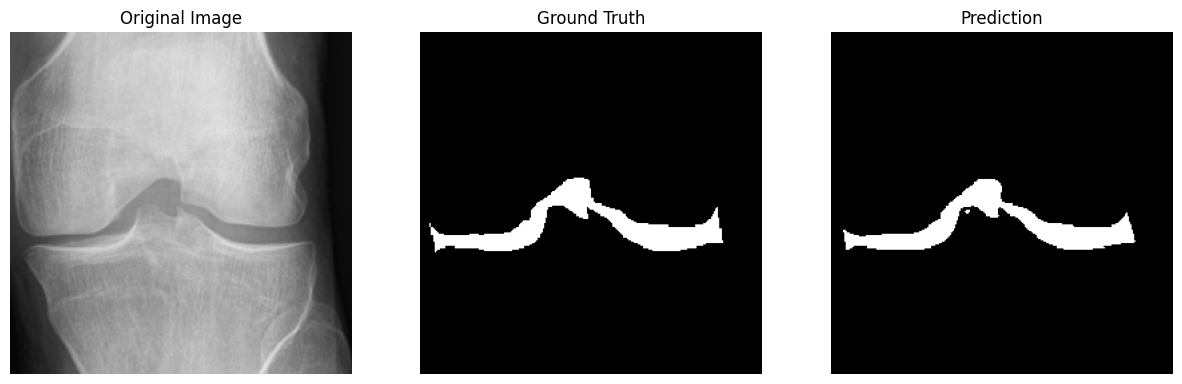

 94%|█████████▍| 75/80 [00:24<00:01,  3.11it/s]

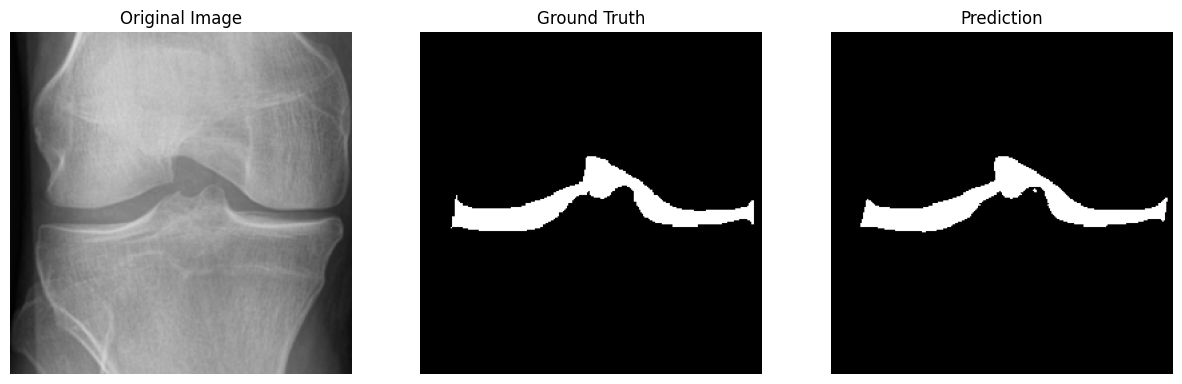

 95%|█████████▌| 76/80 [00:25<00:01,  3.17it/s]

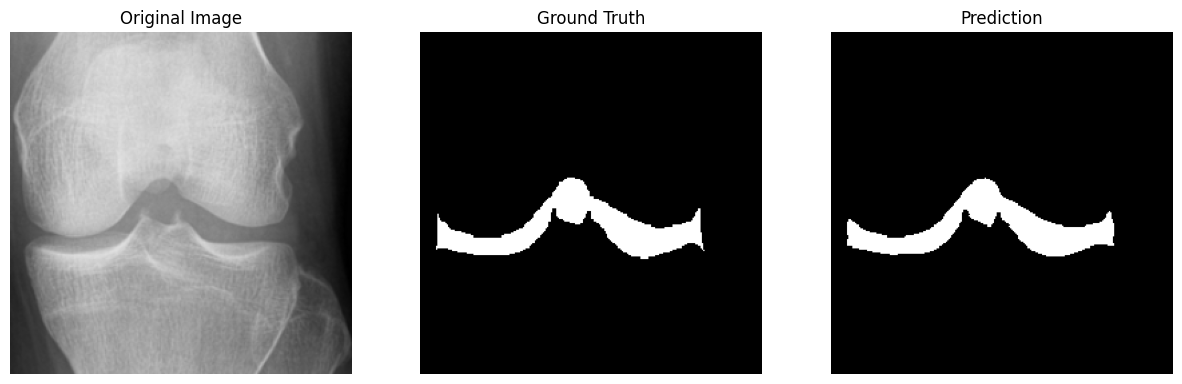

 96%|█████████▋| 77/80 [00:25<00:00,  3.16it/s]

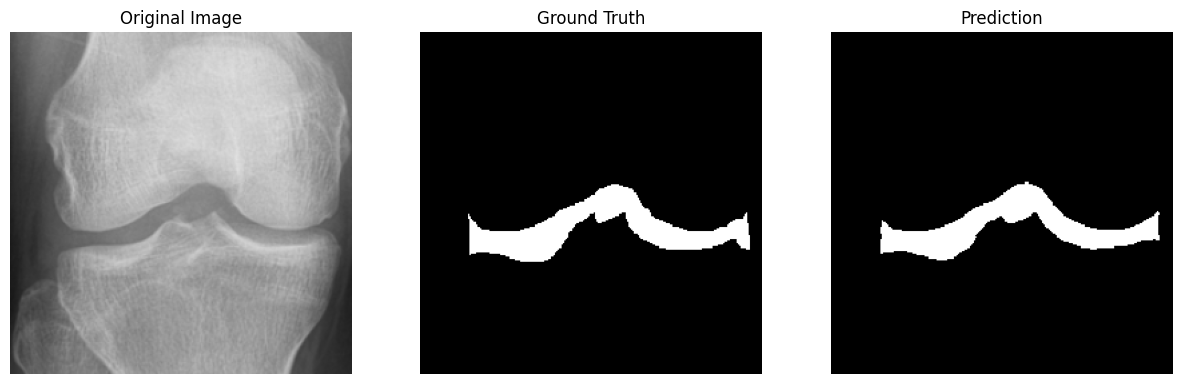

 98%|█████████▊| 78/80 [00:25<00:00,  3.20it/s]

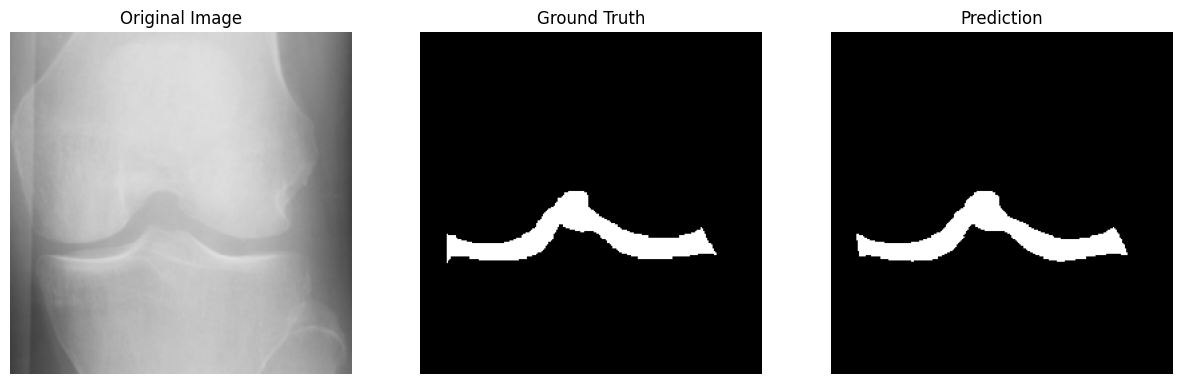

 99%|█████████▉| 79/80 [00:26<00:00,  3.23it/s]

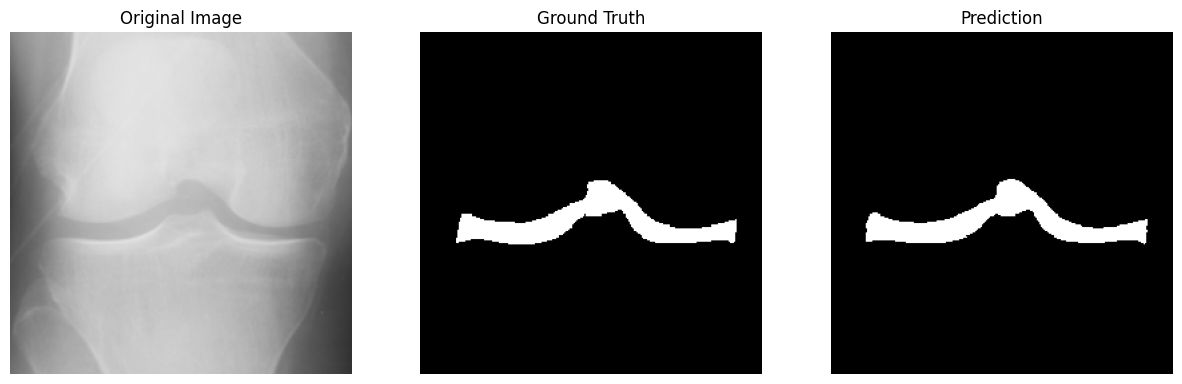

100%|██████████| 80/80 [00:26<00:00,  3.02it/s]


In [ ]:
def visualize_predictions(model, test_dataloader):
    model.to(DEVICE)
    model.eval()

    with torch.no_grad():
        # Loop through the test dataset and visualize a few samples
        for i, (images, masks) in enumerate(tqdm(test_dataloader)):

            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            # Get model predictions
            outputs = model(images)

            # Get predicted labels by taking argmax (for single class prediction)
            preds = torch.argmax(outputs, dim=1)

            # Convert to numpy for visualization
            images = images.cpu().numpy().transpose(0, 2, 3, 1)[0]  # Convert to HWC
            masks = masks.cpu().numpy()[0]  # Convert to HWC
            preds = preds.cpu().numpy()[0]  # Convert to HWC

            # Create subplots to visualize image, ground truth, and prediction
            fig, axes = plt.subplots(1, 3, figsize=(15, 5))

            # Display original image
            axes[0].imshow(images)
            axes[0].set_title("Original Image")
            axes[0].axis("off")

            # Display ground truth
            axes[1].imshow(masks, cmap="grey")
            axes[1].set_title("Ground Truth")
            axes[1].axis("off")

            # Display prediction
            axes[2].imshow(preds, cmap="grey")
            axes[2].set_title("Prediction")
            axes[2].axis("off")

            # Show the plots
            plt.show()

# Visualize predictions on test data
visualize_predictions(model, test_dataloader)

In [ ]:
def evaluate_model(model, test_dataloader):
    model.to(DEVICE)
    model.eval()

    # Store total scores
    dice_scores = []
    iou_scores = []

    # Loop over test dataset
    with torch.no_grad():
        for images, masks in tqdm(test_dataloader):
            # Move images and masks to the appropriate device
            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            # Get model predictions
            outputs = model(images)

            # Calculate metrics
            dice = dice_score(outputs, masks)
            iou = iou_score(outputs, masks)

            dice_scores.append(dice.item())
            iou_scores.append(iou.item())

    # Calculate average metrics over all test samples
    avg_dice_score = np.mean(dice_scores)
    avg_iou_score = np.mean(iou_scores)

    print(f"Test Dice Score: {avg_dice_score:.5f}")
    print(f"Test IoU Score: {avg_iou_score:.5f}")

# Assuming `test_dataloader` is already defined
evaluate_model(model, test_dataloader)

  0%|          | 0/80 [00:00<?, ?it/s]/tmp/ipython-input-970378579.py:39: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(sample["image"]).to(self.device), (torch.tensor(sample["mask"]) / 254).long().to(self.device)
100%|██████████| 80/80 [00:02<00:00, 31.99it/s]

Test Dice Score: 0.96650
Test IoU Score: 0.93720
